<a href="https://colab.research.google.com/github/Thathsara-Devindi/SSTRE-LTNLL/blob/main/LTNLL_Research.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LTNLL Research — Phase 1 + Phase 2

- **Phase 1:** CIFAR-10N `random_label1`, true-class exponential long tail (imbalance factor 10), train/clean validation split, stable sample IDs.
- **Phase 2:** One standard ResNet-18 baseline trained on **observed human-noisy labels** only; evaluate on clean validation, save best/last checkpoints and per-epoch probabilities on the *training* images using deterministic analysis transforms.
- **Future:** Derive confidence (C) and temporal (T) signals from this **same baseline run**. Phase 2 does not implement signal-weighted learning yet.

**Experiment constraints:** CIFAR-10N human-noise + 18,388 training images is a different protocol from the synthetic-noise pilot with 20,431 images. These raw results must not be directly compared as if they were identical conditions.



## 1) Imports + settings

`SEED` Setting a fixed seed value ensures that the dataset selection process is fully reproducible

`IMBALANCE_FACTOR=10`: The sample size ratio between the largest (most frequent) and smallest (least frequent) classes is set to 10:1.

`VAL_PER_CLASS=500`: 500 clean images per class are allocated from the original CIFAR-10 training set to construct the validation set.

In [1]:
import os, json, random
from pathlib import Path
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms

SEED = 42
NUM_CLASSES = 10
IMBALANCE_FACTOR = 10
VAL_PER_CLASS = 500
BATCH_SIZE = 128
NOISE_VARIANT = "random_label1"   # official CIFAR-10N real human-noise labels

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Seed:", SEED)
print("Noise variant:", NOISE_VARIANT)

Device: cuda
Seed: 42
Noise variant: random_label1


## 2) load CIFAR-10 images

CIFAR-10 **original train images 50,000** & **official untouched test images 10,000**. seperate Training augmentation & analysis/evaluation transform

In [2]:
MEAN = (0.4914, 0.4822, 0.4465)
STD  = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

train_raw = datasets.CIFAR10(root='./data', train=True, download=True)
test_dataset = datasets.CIFAR10(root='./data', train=False, download=True,
                               transform=eval_transform)
clean_targets_full = np.asarray(train_raw.targets, dtype=np.int64)

assert len(train_raw) == 50000 and len(test_dataset) == 10000
assert all(np.sum(clean_targets_full == c) == 5000 for c in range(NUM_CLASSES))
print('Original train images:', len(train_raw))
print('Official clean test images:', len(test_dataset))
print('Class names:', train_raw.classes)

100%|██████████| 170M/170M [41:32<00:00, 68.4kB/s]


Original train images: 50000
Official clean test images: 10000
Class names: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 3) load Official **human noisy labels**

Noise Type Update: The previous notebook utilized artificially generated 20% symmetric noise, whereas the current implementation uses the official CIFAR-10N human annotations.

random_label1: This refers to a specific human-annotated noise variant. The actual noise percentage for this variant is calculated dynamically in the output

Data Source: The CIFAR-10_human.pt source file is retrieved directly from the official GitHub repository.



In [3]:
noise_path = Path('./data/CIFAR-10_human.pt')
noise_url = 'https://raw.githubusercontent.com/UCSC-REAL/cifar-10-100n/main/data/CIFAR-10_human.pt'
if not noise_path.exists():
    print('Downloading official CIFAR-10N annotations...')
    urlretrieve(noise_url, noise_path)

assert noise_path.stat().st_size > 100_000, 'Annotation file download looks incomplete.'
# This file is fetched only from the named official CIFAR-10N project
noise_data = torch.load(str(noise_path), map_location='cpu', weights_only=False)
print('Available annotation keys:', list(noise_data.keys()))

human_clean = np.asarray(noise_data['clean_label'], dtype=np.int64)
human_observed_full = np.asarray(noise_data[NOISE_VARIANT], dtype=np.int64)

assert human_clean.shape == (50000,)
assert human_observed_full.shape == (50000,)
assert np.array_equal(human_clean, clean_targets_full), (
    'CIFAR-10 and CIFAR-10N label order do not match. STOP; do not continue.'
)
assert np.all((human_observed_full >= 0) & (human_observed_full < NUM_CLASSES))
print('CIFAR-10N annotation order verified ✅')
print('Full 50k human noise rate:', round(100 * np.mean(human_observed_full != human_clean), 2), '%')

Available annotation keys: ['clean_label', 'aggre_label', 'worse_label', 'random_label1', 'random_label2', 'random_label3']
CIFAR-10N annotation order verified ✅
Full 50k human noise rate: 17.23 %


## 4) Clean validation set **first** separate

Validation Set Allocation: 500 examples per class are extracted from the original training data to construct the validation set

Strict Data Isolation: These validation examples are strictly excluded from the model training process

Dataset Roles: The clean-labeled validation set is utilized exclusively for model selection, while the untouched test set is reserved for final performance reporting


In [4]:
rng_split = np.random.default_rng(SEED)
val_indices_parts = []
train_pool_parts = []

for cls in range(NUM_CLASSES):
    positions = np.where(clean_targets_full == cls)[0]
    rng_split.shuffle(positions)
    val_indices_parts.append(positions[:VAL_PER_CLASS])
    train_pool_parts.append(positions[VAL_PER_CLASS:])

val_indices = np.concatenate(val_indices_parts).astype(np.int64)
train_pool_indices = np.concatenate(train_pool_parts).astype(np.int64)
rng_split.shuffle(val_indices)
rng_split.shuffle(train_pool_indices)

assert len(val_indices) == 5000
assert len(train_pool_indices) == 45000
assert len(np.intersect1d(val_indices, train_pool_indices)) == 0
print('Clean validation:', len(val_indices))
print('Training candidate pool:', len(train_pool_indices))
print('Train/validation overlap: 0 ✅')

Clean validation: 5000
Training candidate pool: 45000
Train/validation overlap: 0 ✅


## 5) create Long-tailed **training** subset

Clean source labels **use for select subset only**. get for training label  *human noisy label* . In Literature used this idea - `long-tail first, noisy noisy labels next`

Preserve Validation class balance , max train-class size eka `4500`

In [5]:
rng_tail = np.random.default_rng(SEED + 1)
MAX_TRAIN_PER_CLASS = 5000 - VAL_PER_CLASS
class_counts_target = [int(MAX_TRAIN_PER_CLASS * (1 / IMBALANCE_FACTOR) **
                          (cls / (NUM_CLASSES - 1))) for cls in range(NUM_CLASSES)]
selected_parts = []
for cls in range(NUM_CLASSES):
    pool_cls = train_pool_indices[clean_targets_full[train_pool_indices] == cls]
    chosen = rng_tail.choice(pool_cls, size=class_counts_target[cls], replace=False)
    selected_parts.append(chosen)

lt_indices = np.concatenate(selected_parts).astype(np.int64)
rng_tail.shuffle(lt_indices)

clean_selected = clean_targets_full[lt_indices]          # Audit only
observed_selected = human_observed_full[lt_indices]      # TRAINING LABELS
is_noisy = observed_selected != clean_selected           # Audit only

assert len(lt_indices) == len(np.unique(lt_indices))
assert len(np.intersect1d(lt_indices, val_indices)) == 0
assert np.array_equal(np.bincount(clean_selected, minlength=NUM_CLASSES),
                      np.asarray(class_counts_target))
print('Long-tail training images:', len(lt_indices))
print('Target sizes by class:', class_counts_target)
print('Human noise rate in selected training set:', round(100*is_noisy.mean(),2), '%')

Long-tail training images: 18388
Target sizes by class: [4500, 3484, 2697, 2088, 1617, 1252, 969, 750, 581, 450]
Human noise rate in selected training set: 17.12 %


## 6) Sample metadata + groups

for Every image have  `local_index` — later `confidence`, `temporal`, `neighborhood` signals attach to correct sample essential.

`true_clean_label` & `is_noisy` data frame  audit only. **Training loop not using as input **

`Head/Medium/Tail`

In [6]:
head_classes = set(range(0, 3))
medium_classes = set(range(3, 7))
tail_classes = set(range(7, 10))

def get_group(cls):
    if cls in head_classes: return 'Head'
    if cls in medium_classes: return 'Medium'
    return 'Tail'

sample_info = pd.DataFrame({
    'local_index': np.arange(len(lt_indices)),
    'original_cifar_index': lt_indices,
    'observed_label': observed_selected,
    'true_clean_label_AUDIT_ONLY': clean_selected,
    'is_noisy_AUDIT_ONLY': is_noisy,
    'group_AUDIT_ONLY': [get_group(int(c)) for c in clean_selected]
})

print(sample_info.groupby('group_AUDIT_ONLY').agg(
    samples=('local_index','size'),
    noise_rate=('is_noisy_AUDIT_ONLY','mean')
).to_string())
print('\nFirst 5 rows:')
print(sample_info.head().to_string(index=False))

                  samples  noise_rate
group_AUDIT_ONLY                     
Head                10681    0.151578
Medium               5926    0.221735
Tail                 1781    0.120719

First 5 rows:
 local_index  original_cifar_index  observed_label  true_clean_label_AUDIT_ONLY  is_noisy_AUDIT_ONLY group_AUDIT_ONLY
           0                   775               2                            2                False             Head
           1                 15623               9                            0                 True             Head
           2                 10601               0                            0                False             Head
           3                 20434               0                            0                False             Head
           4                 17837               7                            7                False             Tail


## 7) Datasets + loaders

**Training:** image + observed noisy label + stable local sample ID.

**Analysis:** same training image IDs, but *without random augmentation* — future confidence/temporal measurements align correctly.

**Validation and test:** clean labels, only for evaluation. **Never backprop on validation/test.**

In [7]:
class IndexedNoisyCifarDataset(Dataset):
    def __init__(self, original_dataset, original_indices, observed_labels, transform):
        self.original_dataset = original_dataset
        self.original_indices = np.asarray(original_indices, dtype=np.int64)
        self.observed_labels = np.asarray(observed_labels, dtype=np.int64)
        self.transform = transform
        assert len(self.original_indices) == len(self.observed_labels)

    def __len__(self):
        return len(self.original_indices)

    def __getitem__(self, local_idx):
        original_idx = int(self.original_indices[local_idx])
        image, _unused_clean_label = self.original_dataset[original_idx]
        image = self.transform(image)
        # IMPORTANT: no clean label returned to the training method
        return image, int(self.observed_labels[local_idx]), int(local_idx)

class IndexedCleanCifarDataset(Dataset):
    def __init__(self, original_dataset, original_indices, transform):
        self.original_dataset = original_dataset
        self.original_indices = np.asarray(original_indices, dtype=np.int64)
        self.transform = transform

    def __len__(self):
        return len(self.original_indices)

    def __getitem__(self, i):
        img, correct_label = self.original_dataset[int(self.original_indices[i])]
        return self.transform(img), int(correct_label)

train_dataset = IndexedNoisyCifarDataset(train_raw, lt_indices, observed_selected, train_transform)
analysis_dataset = IndexedNoisyCifarDataset(train_raw, lt_indices, observed_selected, eval_transform)
val_dataset = IndexedCleanCifarDataset(train_raw, val_indices, eval_transform)

loader_kwargs = {'num_workers': 2, 'pin_memory': (device.type == 'cuda')}
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, **loader_kwargs)
analysis_loader = DataLoader(analysis_dataset, batch_size=256, shuffle=False, **loader_kwargs)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False, **loader_kwargs)

batch = next(iter(train_loader))
print('Train batch image shape:', tuple(batch[0].shape))
print('Observed label shape:', tuple(batch[1].shape))
print('Local IDs shape:', tuple(batch[2].shape))
print('Training dataset length:', len(train_dataset))
print('Analysis dataset length:', len(analysis_dataset))
print('Validation dataset length:', len(val_dataset))
print('Test dataset length:', len(test_dataset))

Train batch image shape: (128, 3, 32, 32)
Observed label shape: (128,)
Local IDs shape: (128,)
Training dataset length: 18388
Analysis dataset length: 18388
Validation dataset length: 5000
Test dataset length: 10000


## 8) Final verification — **RUN THIS BEFORE ANY TRAINING**

Expected:
- Dataset source CIFAR-10N human annotations
- Long-tail class counts decreasing
- Train/validation overlap = zero
- Noise rate actually computed
- Training sample IDs and observed labels aligned
- Training batch shapes correct

**Note:**
Benchmark Comparability: Due to the extraction of a separate validation set in this protocol, the resulting benchmark scores cannot be directly compared with those reported in published papers (which often train on the full dataset).

Documentation: This methodological discrepancy will be explicitly addressed and documented during the subsequent baseline comparison phase.

✅ PHASE 1 CHECKS PASSED
Training samples: 18388
Val samples: 5000
Test samples: 10000
Observed human noise rate: 17.12%


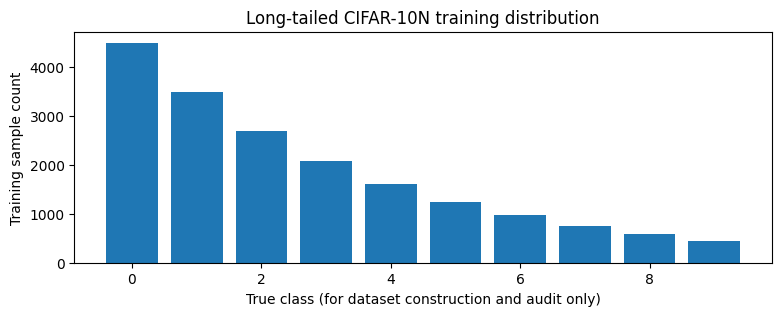

✅ Experiment metadata saved under ./artifacts/ (Colab runtime storage).
IMPORTANT: Save/download these artifacts or copy them to Google Drive before resetting runtime.


In [8]:
assert set(lt_indices).isdisjoint(set(val_indices))
assert len(train_dataset) == len(analysis_dataset) == len(sample_info)
assert len(val_dataset) == 5000 and len(test_dataset) == 10000
assert np.array_equal(sample_info['local_index'].values, np.arange(len(sample_info)))
for sample_id in [0, len(sample_info)//2, len(sample_info)-1]:
    _, observed, returned_id = analysis_dataset[sample_id]
    assert returned_id == sample_id
    assert observed == sample_info.loc[sample_id, 'observed_label']

print('✅ PHASE 1 CHECKS PASSED')
print('Training samples:', len(train_dataset))
print('Val samples:', len(val_dataset))
print('Test samples:', len(test_dataset))
print('Observed human noise rate:', f'{100*is_noisy.mean():.2f}%')

plt.figure(figsize=(9,3))
plt.bar(range(NUM_CLASSES), np.bincount(clean_selected, minlength=NUM_CLASSES))
plt.xlabel('True class (for dataset construction and audit only)')
plt.ylabel('Training sample count')
plt.title('Long-tailed CIFAR-10N training distribution')
plt.show()

os.makedirs('artifacts', exist_ok=True)
sample_info.to_csv('artifacts/dataset_metadata_AUDIT_ONLY.csv', index=False)
np.savez_compressed('artifacts/dataset_split_v2.npz',
                    lt_indices=lt_indices, val_indices=val_indices,
                    observed_labels=observed_selected,
                    clean_labels_AUDIT_ONLY=clean_selected,
                    is_noisy_AUDIT_ONLY=is_noisy)
with open('artifacts/phase1_config.json', 'w') as f:
    json.dump({'seed': SEED, 'dataset': 'CIFAR-10N', 'noise_variant': NOISE_VARIANT,
               'imbalance_factor': IMBALANCE_FACTOR, 'val_per_class': VAL_PER_CLASS,
               'train_size': len(train_dataset), 'actual_noise_rate': float(is_noisy.mean())},
               f, indent=2)
print('✅ Experiment metadata saved under ./artifacts/ (Colab runtime storage).')
print('IMPORTANT: Save/download these artifacts or copy them to Google Drive before resetting runtime.')

# PHASE 1 COMPLETE ✅

If Phase 1 checks above pass, continue with **Phase 2 below in the SAME notebook**. No separate Phase 2 notebook is needed. When Colab restarts, re-run Phase 1 cells to reconstruct the same dataset objects; the saved indices and checkpoint guards below verify consistency.


# Phase 2 — Single ResNet-18 baseline (same notebook)


**No confident or temporal weighting is being applied in Phase 2.** This is the *ordinary* baseline against which the proposed method must later be compared using identical protocols.


## 9) Google Drive connect + Phase 1 split permanent save (do this before training)


In [10]:
import shutil
import hashlib
from pathlib import Path

# 1) Require GPU for Phase 2 (Phase 1 is allowed to run on CPU).
if not torch.cuda.is_available() or device.type != 'cuda':
    raise RuntimeError(
        'Phase 2 needs a GPU. In Colab: Runtime > Change runtime type > T4 GPU, '
        'then run all Phase 1 cells again before this Phase 2 cell.'
    )
print('GPU:', torch.cuda.get_device_name(0))

# 2) Independent of Google Drive: stable identifier for the exact dataset/split/labels.
SPLIT_FINGERPRINT = hashlib.sha256(
    lt_indices.astype('<i8').tobytes()
    + val_indices.astype('<i8').tobytes()
    + observed_selected.astype('<i8').tobytes()
).hexdigest()
print('Split fingerprint:', SPLIT_FINGERPRINT[:16])

# 3) Storage. Try permanent Google Drive first, fall back safely to Colab storage.
USE_GOOGLE_DRIVE = True    # Set False only if Drive authentication cannot be fixed.
STORAGE_PERMANENT = False
if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        mydrive = Path('/content/drive/MyDrive')
        if not mydrive.is_dir():
            raise RuntimeError('Google Drive mount did not expose /content/drive/MyDrive')
        PROJECT_ROOT = mydrive / 'LTNLL_Research'
        STORAGE_PERMANENT = True
    except Exception as exc:
        print('WARNING: Google Drive mount failed:', type(exc).__name__, str(exc))
        PROJECT_ROOT = Path('/content/artifacts/LTNLL_Research')
else:
    PROJECT_ROOT = Path('/content/artifacts/LTNLL_Research')

PHASE1_DRIVE = PROJECT_ROOT / 'Phase1_V2'   # variable name retained for later cells
PHASE2_DRIVE = PROJECT_ROOT / 'Phase2_V2'   # variable name retained for later cells
PHASE1_DRIVE.mkdir(parents=True, exist_ok=True)
PHASE2_DRIVE.mkdir(parents=True, exist_ok=True)

# 4) Preserve exact Phase 1 split, labels and metadata. Check if earlier saved copy differs.
source_dir = Path('artifacts')
required_files = ['dataset_split_v2.npz', 'dataset_metadata_AUDIT_ONLY.csv', 'phase1_config.json']
for filename in required_files:
    source_file = source_dir / filename
    target_file = PHASE1_DRIVE / filename
    if not source_file.is_file():
        raise FileNotFoundError(f'Missing {source_file}. Run Phase 1 through the final check cell first.')
    if target_file.exists():
        if filename.endswith('.npz'):
            with np.load(source_file) as new, np.load(target_file) as old:
                assert set(new.files) == set(old.files) and all(
                    np.array_equal(new[k], old[k]) for k in new.files
                ), f'Dataset split mismatch for {filename}! STOP.'
        elif filename.endswith('.json'):
            assert json.loads(source_file.read_text()) == json.loads(target_file.read_text()), (
                f'Config mismatch for {filename}! STOP.'
            )
        else:
            assert pd.read_csv(source_file).equals(pd.read_csv(target_file)), (
                f'Metadata mismatch for {filename}! STOP.'
            )
        print('Verified existing Phase 1 backup:', filename)
    else:
        shutil.copy2(source_file, target_file)
        print('Saved Phase 1 backup:', filename)

print('Phase 2 output folder:', PHASE2_DRIVE)
print('Permanent Google Drive storage:', STORAGE_PERMANENT)
if not STORAGE_PERMANENT:
    print('IMPORTANT: Local files will be LOST when Colab resets. Download backup after training!')
print('✅ PHASE 2 PREREQUISITES PASSED')


GPU: Tesla T4
Split fingerprint: 9a8f859c87102763
Mounted at /content/drive
Saved Phase 1 backup: dataset_split_v2.npz
Saved Phase 1 backup: dataset_metadata_AUDIT_ONLY.csv
Saved Phase 1 backup: phase1_config.json
Phase 2 output folder: /content/drive/MyDrive/LTNLL_Research/Phase2_V2
Permanent Google Drive storage: True
✅ PHASE 2 PREREQUISITES PASSED


## 10) Fixed baseline hyperparameters + model

- Train: observed `random_label1` human noisy labels (18,388 images), `train_loader` (random crop/flip).
- Validation: **clean 5,000** examples from the separate validation pool, never backpropagated.
- Architecture: ResNet-18 adapted to CIFAR's 32×32 images (`3×3` stem and no max-pool), no ImageNet pretrained weights.
- Baseline: standard cross-entropy, SGD momentum, MultiStepLR. **20 epochs initial controlled protocol**. If the study later requires longer training, change the protocol for **every** method, not just the proposed method.
- Selection: checkpoint with best **validation macro F1**, not test accuracy.
- `analysis_loader` returns `(image, observed_label, local_index)` in a fixed order. Histories from this model are useful for later C/T analyses, but their cleanliness performance is not evaluated yet.


In [11]:
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

P2_EPOCHS = 20
P2_LR = 0.1
P2_MOMENTUM = 0.9
P2_WEIGHT_DECAY = 5e-4
P2_MILESTONES = [12, 17]
P2_GAMMA = 0.1

# Keep all future comparison methods on the SAME agreed settings.
P2_CONFIG = {
    'dataset': 'CIFAR-10N',
    'noise_variant': NOISE_VARIANT,
    'imbalance_factor': IMBALANCE_FACTOR,
    'seed': SEED,
    'split_fingerprint': SPLIT_FINGERPRINT,
    'train_size': len(train_dataset),
    'validation_size': len(val_dataset),
    'epochs': P2_EPOCHS,
    'batch_size': BATCH_SIZE,
    'optimizer': 'SGD',
    'lr': P2_LR,
    'momentum': P2_MOMENTUM,
    'weight_decay': P2_WEIGHT_DECAY,
    'lr_milestones': P2_MILESTONES,
    'lr_gamma': P2_GAMMA,
    'selection_metric': 'validation_macro_f1',
    'backbone': 'ResNet18_CIFAR_no_pretraining',
}
config_path = PHASE2_DRIVE / 'phase2_config.json'
if config_path.exists():
    assert json.loads(config_path.read_text()) == P2_CONFIG, (
        'Saved Phase 2 settings do not match! Use a new experiment folder '
        'for changed settings; do not overwrite existing results.'
    )
else:
    config_path.write_text(json.dumps(P2_CONFIG, indent=2))

# Seed AFTER dataset construction; on restart the checkpoint restores the RNG state.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

def make_resnet18_cifar():
    network = models.resnet18(weights=None)
    network.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    network.maxpool = nn.Identity()
    network.fc = nn.Linear(network.fc.in_features, NUM_CLASSES)
    return network

baseline_model = make_resnet18_cifar().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    baseline_model.parameters(), lr=P2_LR,
    momentum=P2_MOMENTUM, weight_decay=P2_WEIGHT_DECAY
)
scheduler = torch.optim.lr_scheduler.MultiStepLR(
    optimizer, milestones=P2_MILESTONES, gamma=P2_GAMMA
)

print('Model: ResNet-18 (CIFAR stem, no pretrained weights)')
print('Epochs:', P2_EPOCHS, '| batch size:', BATCH_SIZE)
print('Trainable parameters:', sum(p.numel() for p in baseline_model.parameters() if p.requires_grad))
print('Checkpoint selection: validation macro F1; official test set not used.')


Model: ResNet-18 (CIFAR stem, no pretrained weights)
Epochs: 20 | batch size: 128
Trainable parameters: 11173962
Checkpoint selection: validation macro F1; official test set not used.


## 11) Define baseline train/validate/analysis functions

train_one_baseline_epoch: Applies standard cross-entropy loss using the observed noisy labels. The local_index variable is not utilized in the training loss computation.

evaluate_validation: Evaluates the model on the separate, clean validation set using overall accuracy, balanced accuracy, macro F1 score, and group-wise accuracy metrics. The test set is strictly not accessed during this phase.

collect_analysis_probabilities: Records per-epoch predicted class probabilities into the correct matrix rows using a stable local sample ID. This exact mapping is critical; without it, future temporal signal calculations would mistakenly compare predictions of completely different images across epochs.


In [12]:
def train_one_baseline_epoch(model, loader):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total = 0
    for images, observed_labels, _local_ids in loader:
        images = images.to(device, non_blocking=True)
        observed_labels = observed_labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, observed_labels)
        loss.backward()
        optimizer.step()
        batch_n = observed_labels.size(0)
        total_loss += loss.item() * batch_n
        total_correct += (logits.argmax(1) == observed_labels).sum().item()
        total += batch_n
    return total_loss / total, total_correct / total

@torch.inference_mode()
def evaluate_validation(model, loader):
    model.eval()
    true_all, pred_all = [], []
    for images, clean_labels in loader:
        logits = model(images.to(device, non_blocking=True))
        true_all.append(clean_labels.numpy())
        pred_all.append(logits.argmax(1).cpu().numpy())
    y_true = np.concatenate(true_all)
    y_pred = np.concatenate(pred_all)
    group_acc = {}
    for group_name, class_ids in [
        ('head', [0, 1, 2]), ('medium', [3, 4, 5, 6]), ('tail', [7, 8, 9])
    ]:
        mask = np.isin(y_true, class_ids)
        group_acc[f'val_{group_name}_acc'] = float(np.mean(y_true[mask] == y_pred[mask]))
    return {
        'val_accuracy': float(accuracy_score(y_true, y_pred)),
        'val_balanced_accuracy': float(balanced_accuracy_score(y_true, y_pred)),
        'val_macro_f1': float(f1_score(y_true, y_pred, labels=list(range(NUM_CLASSES)),
                                       average='macro', zero_division=0)),
        **group_acc,
    }

@torch.inference_mode()
def collect_analysis_probabilities(model, loader, n_samples):
    model.eval()
    all_probs = np.full((n_samples, NUM_CLASSES), np.nan, dtype=np.float32)
    seen = np.zeros(n_samples, dtype=bool)
    for images, _observed_labels, local_ids in loader:
        logits = model(images.to(device, non_blocking=True))
        probs = F.softmax(logits, dim=1).cpu().numpy()
        ids = local_ids.numpy().astype(np.int64)
        assert np.all((0 <= ids) & (ids < n_samples)), 'Invalid sample ID.'
        assert not np.any(seen[ids]), 'Repeated local sample ID!'
        all_probs[ids] = probs
        seen[ids] = True
    assert np.all(seen), 'Some training images were missing from analysis predictions.'
    assert np.isfinite(all_probs).all()
    assert np.allclose(all_probs.sum(1), 1.0, atol=2e-5)
    return all_probs


## 12) Resume-safe experiment state

Every epoch a `baseline_last.pt` checkpoint will store the model/optimizer/scheduler state **and** historical prediction probabilities. This allows recovery after Colab disconnects. `baseline_best.pt` stores the selected model. Files stay on **your own Google Drive**.

**Security:** Load checkpoints only from your own trusted Drive folder. `torch.load(weights_only=False)` can load pickled content; it must never be used for untrusted downloads.


In [13]:
last_ckpt_path = PHASE2_DRIVE / 'baseline_last.pt'
best_ckpt_path = PHASE2_DRIVE / 'baseline_best.pt'
log_csv_path = PHASE2_DRIVE / 'baseline_training_history.csv'
probs_npz_path = PHASE2_DRIVE / 'baseline_probability_history.npz'

# float16 halves the saved probability-history size; softmax was computed in float32.
probability_history = np.full(
    (P2_EPOCHS, len(train_dataset), NUM_CLASSES), np.nan, dtype=np.float16
)
training_log = []
best_val_f1 = -float('inf')
start_epoch = 0

if last_ckpt_path.exists():
    state = torch.load(last_ckpt_path, map_location=device, weights_only=False)
    assert state['config'] == P2_CONFIG, 'Checkpoint metadata differs; do not resume.'
    baseline_model.load_state_dict(state['model_state_dict'])
    optimizer.load_state_dict(state['optimizer_state_dict'])
    scheduler.load_state_dict(state['scheduler_state_dict'])
    probability_history = state['probability_history']
    training_log = state['training_log']
    best_val_f1 = float(state['best_val_f1'])
    start_epoch = int(state['epoch_completed'])
    if 'torch_rng_state' in state:
        torch.set_rng_state(state['torch_rng_state'].cpu())
    if 'cuda_rng_state_all' in state and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(state['cuda_rng_state_all'])
    if 'numpy_rng_state' in state:
        np.random.set_state(state['numpy_rng_state'])
    if 'python_rng_state' in state:
        random.setstate(state['python_rng_state'])
    assert probability_history.shape == (P2_EPOCHS, len(train_dataset), NUM_CLASSES)
    assert len(training_log) == start_epoch
    print(f'RESUMED from saved epoch {start_epoch} / {P2_EPOCHS}')
else:
    print('No existing matching checkpoint. Starting baseline from epoch 1.')


No existing matching checkpoint. Starting baseline from epoch 1.


## 13) Train baseline + collect prediction history (long-running cell)

Every epoch: train → clean validation metrics → record **same-model** probabilities on entire training set → save best and last checkpoints.

In [14]:
for epoch_index in range(start_epoch, P2_EPOCHS):
    epoch_number = epoch_index + 1
    train_loss, train_observed_acc = train_one_baseline_epoch(baseline_model, train_loader)
    val_metrics = evaluate_validation(baseline_model, val_loader)
    # IMPORTANT: probabilities are from this very same baseline model/epoch,
    # on training images with NO random augmentation.
    p_epoch = collect_analysis_probabilities(baseline_model, analysis_loader, len(train_dataset))
    probability_history[epoch_index] = p_epoch.astype(np.float16)

    log_row = {
        'epoch': epoch_number,
        'train_noisy_label_loss': float(train_loss),
        'train_observed_label_accuracy': float(train_observed_acc),
        'lr': float(optimizer.param_groups[0]['lr']),
        **val_metrics,
    }
    training_log.append(log_row)

    improved = val_metrics['val_macro_f1'] > best_val_f1
    if improved:
        best_val_f1 = val_metrics['val_macro_f1']
        torch.save({
            'model_state_dict': baseline_model.state_dict(),
            'epoch': epoch_number,
            'best_val_macro_f1': best_val_f1,
            'config': P2_CONFIG,
        }, best_ckpt_path)

    scheduler.step()
    torch.save({
        'epoch_completed': epoch_number,
        'model_state_dict': baseline_model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'probability_history': probability_history,
        'training_log': training_log,
        'best_val_f1': best_val_f1,
        'config': P2_CONFIG,
        'torch_rng_state': torch.get_rng_state(),
        'cuda_rng_state_all': torch.cuda.get_rng_state_all(),
        'numpy_rng_state': np.random.get_state(),
        'python_rng_state': random.getstate(),
    }, last_ckpt_path)
    pd.DataFrame(training_log).to_csv(log_csv_path, index=False)

    print(
        f"Epoch {epoch_number:02d}/{P2_EPOCHS} | "
        f"train loss {train_loss:.4f} | "
        f"train obs-acc {train_observed_acc:.2%} | "
        f"val acc {val_metrics['val_accuracy']:.2%} | "
        f"val macro-F1 {val_metrics['val_macro_f1']:.4f} | "
        f"val tail acc {val_metrics['val_tail_acc']:.2%}"
        + (' | saved BEST' if improved else '')
    )

# Compact portable history file for Phase 3 (confidence/temporal analysis).
completed_epochs = len(training_log)
assert completed_epochs == P2_EPOCHS, f'Only {completed_epochs}/{P2_EPOCHS} completed.'
np.savez_compressed(
    probs_npz_path,
    probability_history=probability_history,
    selected_train_original_indices=lt_indices,
    observed_training_labels=observed_selected,
    split_fingerprint=np.array(SPLIT_FINGERPRINT),
)
print('\nBASELINE TRAINING COMPLETE ✅')
print('Saved best model:', best_ckpt_path)
print('Saved last model:', last_ckpt_path)
print('Saved probability history:', probs_npz_path)


Epoch 01/20 | train loss 2.6020 | train obs-acc 23.69% | val acc 17.30% | val macro-F1 0.0854 | val tail acc 0.00% | saved BEST
Epoch 02/20 | train loss 1.8953 | train obs-acc 32.58% | val acc 21.36% | val macro-F1 0.1013 | val tail acc 0.00% | saved BEST
Epoch 03/20 | train loss 1.7755 | train obs-acc 36.86% | val acc 23.32% | val macro-F1 0.1325 | val tail acc 0.00% | saved BEST
Epoch 04/20 | train loss 1.7036 | train obs-acc 39.65% | val acc 26.48% | val macro-F1 0.1879 | val tail acc 6.33% | saved BEST
Epoch 05/20 | train loss 1.6289 | train obs-acc 43.50% | val acc 32.20% | val macro-F1 0.2524 | val tail acc 4.47% | saved BEST
Epoch 06/20 | train loss 1.5742 | train obs-acc 45.74% | val acc 34.68% | val macro-F1 0.2952 | val tail acc 10.73% | saved BEST
Epoch 07/20 | train loss 1.5370 | train obs-acc 47.47% | val acc 36.28% | val macro-F1 0.3096 | val tail acc 8.07% | saved BEST
Epoch 08/20 | train loss 1.4994 | train obs-acc 49.16% | val acc 38.08% | val macro-F1 0.3249 | val tai

## 14) Final Phase 2 checks + charts

The following **are validation results only**, not test results. Phase 3 can later load `baseline_probability_history.npz` (no retraining required) to compute confidence and temporal scores. All phases are connected by stable local sample indices and the identical split fingerprint.


,epoch,train_noisy_label_loss,train_observed_label_accuracy,lr,val_accuracy,val_balanced_accuracy,val_macro_f1,val_head_acc,val_medium_acc,val_tail_acc
15,16,1.187352,0.615564,0.010,0.6086,0.6086,0.606166,0.831333,0.5160,0.509333
16,17,1.174906,0.619698,0.010,0.5970,0.5970,0.593756,0.833333,0.4920,0.500667
17,18,1.145967,0.632967,0.001,0.6230,0.6230,0.620460,0.824000,0.5360,0.538000
18,19,1.137384,0.638677,0.001,0.6274,0.6274,0.624787,0.828000,0.5430,0.539333
19,20,1.130144,0.639330,0.001,0.6300,0.6300,0.628311,0.823333,0.5485,0.545333


Best validation epoch: 20
Best validation macro-F1: 0.6283
Best validation accuracy: 63.00%
Best validation tail accuracy: 54.53%
Stored probability history: (20, 18388, 10)
Official CIFAR-10 test set: NOT evaluated in Phase 2


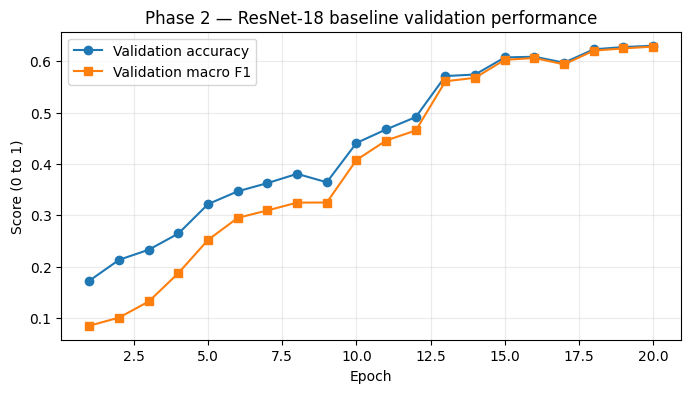

✅ PHASE 2 CHECKS PASSED


In [15]:
assert best_ckpt_path.exists() and last_ckpt_path.exists()
assert probs_npz_path.exists() and log_csv_path.exists()
assert len(training_log) == P2_EPOCHS
assert np.isfinite(probability_history.astype(np.float32)).all()
assert np.allclose(probability_history.astype(np.float32).sum(2), 1.0, atol=0.002)

with np.load(probs_npz_path) as saved:
    assert saved['probability_history'].shape == (P2_EPOCHS, len(train_dataset), NUM_CLASSES)
    assert np.array_equal(saved['selected_train_original_indices'], lt_indices)
    assert np.array_equal(saved['observed_training_labels'], observed_selected)
    assert str(saved['split_fingerprint']) == SPLIT_FINGERPRINT

training_history_df = pd.DataFrame(training_log)
display(training_history_df.tail(5))
best_row = training_history_df.loc[training_history_df['val_macro_f1'].idxmax()]
print('Best validation epoch:', int(best_row['epoch']))
print('Best validation macro-F1:', round(float(best_row['val_macro_f1']), 4))
print('Best validation accuracy:', f"{float(best_row['val_accuracy']):.2%}")
print('Best validation tail accuracy:', f"{float(best_row['val_tail_acc']):.2%}")
print('Stored probability history:', probability_history.shape)
print('Official CIFAR-10 test set: NOT evaluated in Phase 2')

plt.figure(figsize=(8, 4))
plt.plot(training_history_df['epoch'], training_history_df['val_accuracy'],
         marker='o', label='Validation accuracy')
plt.plot(training_history_df['epoch'], training_history_df['val_macro_f1'],
         marker='s', label='Validation macro F1')
plt.xlabel('Epoch')
plt.ylabel('Score (0 to 1)')
plt.title('Phase 2 — ResNet-18 baseline validation performance')
plt.legend()
plt.grid(alpha=0.25)
plt.show()
print('✅ PHASE 2 CHECKS PASSED')


`PHASE 2 CHECKS PASSED`, **(2)** last five training-log rows and best validation metrics, **(3)** any Colab error. Then we will evaluate **Confidence (C)** and **Temporal (T)** from **this same saved prediction history**, without training two unrelated baselines.




#Phase 3 — Confidence (C), Temporal (T), and Reliability Audit

In [1]:
# Load saved Phase 1/2 artifacts, even after a Colab restart
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy.stats import spearmanr

# Normally leave this as None. Only change it if your project folder is somewhere else.
PHASE3_PROJECT_ROOT_OVERRIDE = None

root_candidates = []
if PHASE3_PROJECT_ROOT_OVERRIDE is not None:
    root_candidates.append(Path(PHASE3_PROJECT_ROOT_OVERRIDE))
root_candidates.extend([
    Path('/content/drive/MyDrive/LTNLL_Research'),
    Path('/content/artifacts/LTNLL_Research'),
])

def contains_phase3_inputs(root):
    return (
        (root / 'Phase1_V2' / 'dataset_split_v2.npz').is_file()
        and (root / 'Phase2_V2' / 'baseline_probability_history.npz').is_file()
        and (root / 'Phase2_V2' / 'baseline_training_history.csv').is_file()
        and (root / 'Phase2_V2' / 'phase2_config.json').is_file()
    )

P3_ROOT = next((r for r in root_candidates if contains_phase3_inputs(r)), None)
if P3_ROOT is None and PHASE3_PROJECT_ROOT_OVERRIDE is None:
    # Mount Drive only if the files were not visible already.
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except (ImportError, RuntimeError, ValueError, OSError) as exc:
        print('Drive not mounted:', str(exc))
    P3_ROOT = next((r for r in root_candidates if contains_phase3_inputs(r)), None)

if P3_ROOT is None:
    raise FileNotFoundError(
        'Phase 3 inputs not found. Check MyDrive/LTNLL_Research/Phase1_V2 '
        'and Phase2_V2 folders. Needed: Phase 1 dataset_split_v2.npz; '
        'Phase 2 baseline_probability_history.npz, baseline_training_history.csv, '
        'phase2_config.json. Do not regenerate a different split.'
    )

P3_DATA_PATH = P3_ROOT / 'Phase1_V2' / 'dataset_split_v2.npz'
P3_HISTORY_PATH = P3_ROOT / 'Phase2_V2' / 'baseline_probability_history.npz'
P3_LOG_PATH = P3_ROOT / 'Phase2_V2' / 'baseline_training_history.csv'
P3_CONFIG_PATH = P3_ROOT / 'Phase2_V2' / 'phase2_config.json'
P3_OUTPUT_DIR = P3_ROOT / 'Phase3_V2'
P3_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

with np.load(P3_DATA_PATH, allow_pickle=False) as ds:
    p3_indices = ds['lt_indices'].astype(np.int64)
    p3_val_indices = ds['val_indices'].astype(np.int64)
    p3_observed = ds['observed_labels'].astype(np.int64)
    p3_clean_AUDIT_ONLY = ds['clean_labels_AUDIT_ONLY'].astype(np.int64)
    p3_is_noisy_AUDIT_ONLY = ds['is_noisy_AUDIT_ONLY'].astype(bool)

with np.load(P3_HISTORY_PATH, allow_pickle=False) as h:
    p3_probs = h['probability_history'].astype(np.float32)
    p3_history_indices = h['selected_train_original_indices'].astype(np.int64)
    p3_history_observed = h['observed_training_labels'].astype(np.int64)
    p3_saved_fingerprint = str(h['split_fingerprint'].item())

p3_train_log = pd.read_csv(P3_LOG_PATH)
p3_config = json.loads(P3_CONFIG_PATH.read_text())
p3_expected_fingerprint = hashlib.sha256(
    p3_indices.astype('<i8').tobytes()
    + p3_val_indices.astype('<i8').tobytes()
    + p3_observed.astype('<i8').tobytes()
).hexdigest()

n_samples = len(p3_observed)
n_epochs, n_history_samples, n_classes = p3_probs.shape
assert n_epochs >= 6, 'At least six saved epochs are required for this analysis.'
assert n_classes == 10, 'Expected CIFAR-10N with 10 classes.'
assert n_samples == n_history_samples and n_samples == p3_config['train_size']
assert n_epochs == int(p3_config['epochs'])
assert np.array_equal(p3_history_indices, p3_indices)
assert np.array_equal(p3_history_observed, p3_observed)
assert p3_saved_fingerprint == p3_expected_fingerprint == p3_config['split_fingerprint']
assert np.array_equal(p3_is_noisy_AUDIT_ONLY, p3_observed != p3_clean_AUDIT_ONLY)
assert len(np.unique(p3_indices)) == n_samples
assert np.intersect1d(p3_indices, p3_val_indices).size == 0
assert np.isfinite(p3_probs).all()
assert np.min(p3_probs) >= 0 and np.max(p3_probs) <= 1
assert np.allclose(p3_probs.sum(axis=2), 1., atol=0.002), 'Saved probabilities are invalid.'
assert len(p3_train_log) == n_epochs
assert np.array_equal(p3_train_log['epoch'].to_numpy(), np.arange(1, n_epochs+1))

# This epoch was selected by clean VALIDATION macro-F1, not by training-clean audit labels.
p3_anchor_epoch = int(p3_train_log.loc[p3_train_log['val_macro_f1'].idxmax(), 'epoch'])
assert 6 <= p3_anchor_epoch <= n_epochs, 'Need >=6 epochs at the validation-selected checkpoint.'

print('PHASE 3 INPUTS VERIFIED')
print('Root:', P3_ROOT)
print('Train images:', n_samples, '| epochs:', n_epochs, '| classes:', n_classes)
print('Using validation-selected epoch:', p3_anchor_epoch)
print('Split fingerprint:', p3_expected_fingerprint[:16])
print('Human noise rate (AUDIT ONLY):', f'{100*p3_is_noisy_AUDIT_ONLY.mean():.2f}%')
print('Phase 3 results folder:', P3_OUTPUT_DIR)

Mounted at /content/drive
PHASE 3 INPUTS VERIFIED
Root: /content/drive/MyDrive/LTNLL_Research
Train images: 18388 | epochs: 20 | classes: 10
Using validation-selected epoch: 20
Split fingerprint: 9a8f859c87102763
Human noise rate (AUDIT ONLY): 17.12%
Phase 3 results folder: /content/drive/MyDrive/LTNLL_Research/Phase3_V2


#Compute confidence and three clearly different temporal signals

The scores here use only the observed training label and the baseline's stored predictions. Ground-truth clean labels are completely absent from the score calculations.
- C: observed-label probability at the validation-selected epoch.
- T_v0: fraction of consecutive epochs with the same predicted class among six recent epochs, including current.
- T_v1: 1 − Jensen–Shannon distance between current probability and the EMA of previous epochs, with EMA factor 0.8.
- T_v2: fraction of predictions equal to the observed training label over the five epochs before current.
None of these is automatically a good cleanliness estimator:  will test the hypothesis rather than assume it

In [2]:
# Indices in p3_probs are zero-based. The anchor epoch is one-based.
p3_current = p3_probs[p3_anchor_epoch - 1]          # (N, 10)
p3_C = p3_current[np.arange(n_samples), p3_observed]

P3_WINDOW = 5
p3_recent_classes = p3_probs[p3_anchor_epoch-(P3_WINDOW+1):p3_anchor_epoch].argmax(axis=2)
assert p3_recent_classes.shape == (P3_WINDOW+1, n_samples)
p3_T_v0 = (p3_recent_classes[1:] == p3_recent_classes[:-1]).mean(axis=0)

# Historical EMA excludes current epoch: no look-ahead / self-comparison.
P3_EMA_ALPHA = 0.8
p3_historical_ema = p3_probs[0].astype(np.float64).copy()
for t in range(1, p3_anchor_epoch-1):
    p3_historical_ema = P3_EMA_ALPHA * p3_historical_ema + (1-P3_EMA_ALPHA) * p3_probs[t]

def js_similarity_batch(p, q):
    # JS distance in base 2 lies in [0, 1]; 1-distance is a similarity.
    eps = 1e-12
    p = np.clip(p.astype(np.float64), eps, 1.)
    q = np.clip(q.astype(np.float64), eps, 1.)
    p = p / p.sum(axis=1, keepdims=True)
    q = q / q.sum(axis=1, keepdims=True)
    m = 0.5 * (p + q)
    js_div = 0.5 * np.sum(p * np.log2(p/m), axis=1) + 0.5 * np.sum(q * np.log2(q/m), axis=1)
    return np.clip(1. - np.sqrt(np.clip(js_div, 0., 1.)), 0., 1.)

p3_T_v1 = js_similarity_batch(p3_current, p3_historical_ema)

# T-v2 deliberately considers observed-label agreement, not just prediction stability.
# Use five *past* epochs, excluding current epoch.
p3_past_classes = p3_probs[p3_anchor_epoch-(P3_WINDOW+1):p3_anchor_epoch-1].argmax(axis=2)
assert p3_past_classes.shape == (P3_WINDOW, n_samples)
p3_T_v2 = (p3_past_classes == p3_observed[None, :]).mean(axis=0)

P3_SIGNALS = {
    'C': p3_C,
    'T_v0_class_stability': p3_T_v0,
    'T_v1_JS_EMA': p3_T_v1,
    'T_v2_past_label_agreement': p3_T_v2,
}
for name, values in P3_SIGNALS.items():
    assert values.shape == (n_samples,), name
    assert np.isfinite(values).all(), name
    assert np.min(values) >= 0 and np.max(values) <= 1, name
    print(f'{name:27s} mean={values.mean():.4f}  std={values.std():.4f}  range=[{values.min():.3f}, {values.max():.3f}]')

print('All Phase 3 scores use predictions/OBSERVED labels only; no clean-label leakage.')

C                           mean=0.5110  std=0.3140  range=[0.000, 0.997]
T_v0_class_stability        mean=0.9298  std=0.1601  range=[0.000, 1.000]
T_v1_JS_EMA                 mean=0.9001  std=0.0426  range=[0.708, 0.991]
T_v2_past_label_agreement   mean=0.6418  std=0.4541  range=[0.000, 1.000]
All Phase 3 scores use predictions/OBSERVED labels only; no clean-label leakage.


#Audit-only clean/noisy AUROC and Average Precision

Evaluation uses the reserved Phase 1 audit labels only after scores have been computed. Positive class = clean observed label (clean=1). Do not use these audit fields for training or weight optimization.

AP must be interpreted relative to the clean proportion: if about 83% of samples are clean, a non-informative score can still have AP around 0.83. AUROC near 0.50 means near-random ranking; AUROC below 0.50 means the scoring direction is reversed in that setting.

In [3]:
p3_is_clean_AUDIT_ONLY = ~p3_is_noisy_AUDIT_ONLY
p3_group_AUDIT_ONLY = np.where(
    p3_clean_AUDIT_ONLY <= 2, 'Head',
    np.where(p3_clean_AUDIT_ONLY <= 6, 'Medium', 'Tail')
)

def audit_roc_ap(score, mask):
    y = p3_is_clean_AUDIT_ONLY[mask].astype(int)
    s = np.asarray(score)[mask]
    return {
        'n': int(mask.sum()),
        'clean_prevalence': float(y.mean()),
        'clean_AUROC': float(roc_auc_score(y, s)) if np.unique(y).size == 2 else np.nan,
        'clean_AP': float(average_precision_score(y, s)) if y.sum() > 0 else np.nan,
    }

p3_group_masks = {
    'All': np.ones(n_samples, dtype=bool),
    'Head': p3_group_AUDIT_ONLY == 'Head',
    'Medium': p3_group_AUDIT_ONLY == 'Medium',
    'Tail': p3_group_AUDIT_ONLY == 'Tail',
}

p3_rows = []
for score_name, score in P3_SIGNALS.items():
    for group_name, group_mask in p3_group_masks.items():
        p3_rows.append({'score': score_name, 'group': group_name, **audit_roc_ap(score, group_mask)})
p3_roc_ap_table = pd.DataFrame(p3_rows)
print('AUROC and AP (positive class = clean observed label):')
print(p3_roc_ap_table.round(4).to_string(index=False))

AUROC and AP (positive class = clean observed label):
                    score  group     n  clean_prevalence  clean_AUROC  clean_AP
                        C    All 18388            0.8288       0.9035    0.9764
                        C   Head 10681            0.8484       0.9483    0.9893
                        C Medium  5926            0.7783       0.8309    0.9356
                        C   Tail  1781            0.8793       0.8093    0.9654
     T_v0_class_stability    All 18388            0.8288       0.5343    0.8391
     T_v0_class_stability   Head 10681            0.8484       0.5318    0.8569
     T_v0_class_stability Medium  5926            0.7783       0.5242    0.7873
     T_v0_class_stability   Tail  1781            0.8793       0.5145    0.8824
              T_v1_JS_EMA    All 18388            0.8288       0.4667    0.8181
              T_v1_JS_EMA   Head 10681            0.8484       0.4837    0.8412
              T_v1_JS_EMA Medium  5926            0.7783       0.4

#Fixed-coverage sample-selection audit and clean-tail false rejection

As a transparent diagnostic example, select the top 70% of samples by each score. This coverage is fixed in advance; it is not tuned to clean labels. The samples not selected are counted as rejected by this hypothetical selector; the baseline model did not actually reject samples while training.

report (a) clean precision, (b) clean recall, (c) clean-tail recall, (d) fraction of clean tail samples hypothetically rejected.

In [4]:
P3_COVERAGE = 0.70

def audit_selection_metrics(score, coverage=P3_COVERAGE):
    score = np.asarray(score)
    k = max(1, int(np.floor(len(score) * coverage)))
    # Deterministic tie break by local sample ID, and exactly k selected samples.
    rank = np.lexsort((np.arange(len(score)), -score))
    selected = np.zeros(len(score), dtype=bool)
    selected[rank[:k]] = True
    clean = p3_is_clean_AUDIT_ONLY
    clean_tail = clean & (p3_group_AUDIT_ONLY == 'Tail')
    return selected, {
        'selected_total': int(k),
        'selection_clean_precision': float(clean[selected].mean()),
        'selection_clean_recall': float(selected[clean].mean()),
        'clean_tail_recall': float(selected[clean_tail].mean()),
        'clean_tail_false_rejection_rate': float((~selected[clean_tail]).mean()),
    }

p3_selection_rows = []
for name, signal in P3_SIGNALS.items():
    _, metrics = audit_selection_metrics(signal)
    p3_selection_rows.append({'score': name, 'coverage': P3_COVERAGE, **metrics})
p3_selection_table = pd.DataFrame(p3_selection_rows)
print('Hypothetical sample selection (70% kept):')
print(p3_selection_table.round(4).to_string(index=False))
print('NOTE: selection is OFFLINE DIAGNOSTIC only; no samples were dropped during baseline training.')

Hypothetical sample selection (70% kept):
                    score  coverage  selected_total  selection_clean_precision  selection_clean_recall  clean_tail_recall  clean_tail_false_rejection_rate
                        C       0.7           12871                     0.9589                  0.8098             0.7088                           0.2912
     T_v0_class_stability       0.7           12871                     0.8403                  0.7096             0.6679                           0.3321
              T_v1_JS_EMA       0.7           12871                     0.8170                  0.6900             0.3921                           0.6079
T_v2_past_label_agreement       0.7           12871                     0.9588                  0.8098             0.6596                           0.3404
NOTE: selection is OFFLINE DIAGNOSTIC only; no samples were dropped during baseline training.


#A cautious exploratory "hard clean tail" proxy

To make the research question measurable, we predefine the proxy as: Tail AND clean AND in the bottom 25% of observed-label confidence at epoch 5. Epoch-5 probabilities existed before the analysis checkpoint. Both tail-group membership and actual clean status are audit-only. This is not a trainable/sample-selection signal. We compare how often the scores would exclude these difficult examples at the same 70% coverage.

In [5]:
P3_HARD_REFERENCE_EPOCH = min(5, p3_anchor_epoch-1)
p3_early_conf = p3_probs[P3_HARD_REFERENCE_EPOCH-1, np.arange(n_samples), p3_observed]
p3_clean_tail_AUDIT_ONLY = p3_is_clean_AUDIT_ONLY & (p3_group_AUDIT_ONLY == 'Tail')
assert p3_clean_tail_AUDIT_ONLY.sum() > 0
hard_cut = float(np.quantile(p3_early_conf[p3_clean_tail_AUDIT_ONLY], 0.25))
p3_hard_clean_tail_AUDIT_ONLY = p3_clean_tail_AUDIT_ONLY & (p3_early_conf <= hard_cut)
assert 0 < p3_hard_clean_tail_AUDIT_ONLY.sum() < p3_clean_tail_AUDIT_ONLY.sum()

hard_results = []
for name, score in P3_SIGNALS.items():
    selected, _ = audit_selection_metrics(score)
    hard_results.append({
        'score': name,
        'hard_clean_tail_n': int(p3_hard_clean_tail_AUDIT_ONLY.sum()),
        'hard_clean_tail_recall': float(selected[p3_hard_clean_tail_AUDIT_ONLY].mean()),
        'hard_clean_tail_false_rejection_rate': float((~selected[p3_hard_clean_tail_AUDIT_ONLY]).mean()),
    })
p3_hard_table = pd.DataFrame(hard_results)
print('Hardness audit reference epoch:', P3_HARD_REFERENCE_EPOCH)
print('Clean tail count:', int(p3_clean_tail_AUDIT_ONLY.sum()))
print('Hard clean tail proxy count:', int(p3_hard_clean_tail_AUDIT_ONLY.sum()))
print('Hardness confidence cutoff (epoch 5):', round(hard_cut, 4))
print(p3_hard_table.round(4).to_string(index=False))
print('WARNING: This is a descriptive definition; selecting it by early confidence may be correlated with C.')

Hardness audit reference epoch: 5
Clean tail count: 1566
Hard clean tail proxy count: 392
Hardness confidence cutoff (epoch 5): 0.0666
                    score  hard_clean_tail_n  hard_clean_tail_recall  hard_clean_tail_false_rejection_rate
                        C                392                  0.4260                                0.5740
     T_v0_class_stability                392                  0.5587                                0.4413
              T_v1_JS_EMA                392                  0.4923                                0.5077
T_v2_past_label_agreement                392                  0.3929                                0.6071


#Does temporal information add anything beyond confidence?

For an interpretable fixed-weight diagnostic only, compare the same C against three 0.5 × C + 0.5 × T variants. These are not proposed stage-aware weights and do not retrain ResNet-18.

All raw scores already lie in [0,1]. Correlation between C and T is measured by Spearman rank correlation. Report improvements/decreases relative to C, including tail AUROC and clean-tail false rejection. Do not choose your final signal by optimizing on these clean-label audit results.

In [6]:
p3_fixed_fusions = {
    'C_plus_Tv0_fixed_50_50': 0.5*p3_C + 0.5*p3_T_v0,
    'C_plus_Tv1_fixed_50_50': 0.5*p3_C + 0.5*p3_T_v1,
    'C_plus_Tv2_fixed_50_50': 0.5*p3_C + 0.5*p3_T_v2,
}
p3_all_scores = {**P3_SIGNALS, **p3_fixed_fusions}

p3_comp_rows = []
for name, score in p3_all_scores.items():
    all_metric = audit_roc_ap(score, p3_group_masks['All'])
    tail_metric = audit_roc_ap(score, p3_group_masks['Tail'])
    _, sel_metric = audit_selection_metrics(score)
    selected, _ = audit_selection_metrics(score)
    p3_comp_rows.append({
        'score': name,
        'overall_AUROC': all_metric['clean_AUROC'],
        'tail_AUROC': tail_metric['clean_AUROC'],
        'clean_tail_false_rejection': sel_metric['clean_tail_false_rejection_rate'],
        'hard_clean_tail_false_rejection': float((~selected[p3_hard_clean_tail_AUDIT_ONLY]).mean()),
    })
p3_comparison = pd.DataFrame(p3_comp_rows)
base_all_auc = p3_comparison.loc[p3_comparison.score == 'C','overall_AUROC'].iloc[0]
base_tail_auc = p3_comparison.loc[p3_comparison.score == 'C','tail_AUROC'].iloc[0]
p3_comparison['delta_overall_AUROC_vs_C'] = p3_comparison['overall_AUROC'] - base_all_auc
p3_comparison['delta_tail_AUROC_vs_C'] = p3_comparison['tail_AUROC'] - base_tail_auc
print(p3_comparison.round(4).to_string(index=False))
print('\nCorrelation with current confidence (higher absolute rho = more redundant rank information):')
for name, values in list(P3_SIGNALS.items())[1:]:
    rho = float(spearmanr(p3_C, values).statistic)
    print(f'{name:27s} Spearman rho = {rho:.4f}')
print('\nThese results are exploratory TRAIN-SPLIT diagnostics, not final unbiased claims.')

                    score  overall_AUROC  tail_AUROC  clean_tail_false_rejection  hard_clean_tail_false_rejection  delta_overall_AUROC_vs_C  delta_tail_AUROC_vs_C
                        C         0.9035      0.8093                      0.2912                           0.5740                    0.0000                 0.0000
     T_v0_class_stability         0.5343      0.5145                      0.3321                           0.4413                   -0.3691                -0.2948
              T_v1_JS_EMA         0.4667      0.3577                      0.6079                           0.5077                   -0.4367                -0.4516
T_v2_past_label_agreement         0.8477      0.7072                      0.3404                           0.6071                   -0.0557                -0.1021
   C_plus_Tv0_fixed_50_50         0.8428      0.7561                      0.2931                           0.5306                   -0.0607                -0.0533
   C_plus_Tv1_fixed_50

#Visual diagnostics + preserve reproducible outputs
The saved score table is labeled AUDIT_ONLY: it includes clean/noisy ground truth solely for analysis. Never use its audit columns to compute training losses, thresholds or learned dynamic weights. Future phases should compute real-time C/T/N from the current model without looking ahead to future epochs.

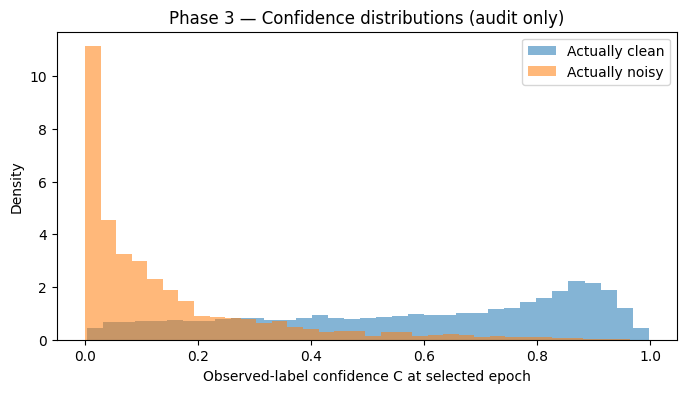

Saved scores -> /content/drive/MyDrive/LTNLL_Research/Phase3_V2/phase3_scores_AUDIT_ONLY.csv
Saved roc_ap -> /content/drive/MyDrive/LTNLL_Research/Phase3_V2/phase3_AUROC_AP_AUDIT_ONLY.csv
Saved selection -> /content/drive/MyDrive/LTNLL_Research/Phase3_V2/phase3_selection_AUDIT_ONLY.csv
Saved hard_tail -> /content/drive/MyDrive/LTNLL_Research/Phase3_V2/phase3_hard_tail_AUDIT_ONLY.csv
Saved comparison -> /content/drive/MyDrive/LTNLL_Research/Phase3_V2/phase3_fixed_fusion_comparison_AUDIT_ONLY.csv
Saved config -> /content/drive/MyDrive/LTNLL_Research/Phase3_V2/phase3_analysis_config.json

✅ PHASE 3 OFFLINE ANALYSIS CHECKS PASSED
No model was retrained. Official CIFAR-10 test set was not used.
Share this notebook with outputs to review C/T usefulness before Phase 4 (Neighborhood N).


In [7]:
plt.figure(figsize=(8,4))
plt.hist(p3_C[p3_is_clean_AUDIT_ONLY], bins=35, alpha=0.55, density=True, label='Actually clean')
plt.hist(p3_C[~p3_is_clean_AUDIT_ONLY], bins=35, alpha=0.55, density=True, label='Actually noisy')
plt.xlabel('Observed-label confidence C at selected epoch')
plt.ylabel('Density')
plt.title('Phase 3 — Confidence distributions (audit only)')
plt.legend()
plt.show()

p3_phase3_results = pd.DataFrame({
    'local_sample_id': np.arange(n_samples, dtype=np.int64),
    'original_cifar_index': p3_indices,
    'observed_label': p3_observed,
    'C': p3_C,
    'T_v0_class_stability': p3_T_v0,
    'T_v1_JS_EMA': p3_T_v1,
    'T_v2_past_label_agreement': p3_T_v2,
    **p3_fixed_fusions,
    'true_clean_label_AUDIT_ONLY': p3_clean_AUDIT_ONLY,
    'is_noisy_AUDIT_ONLY': p3_is_noisy_AUDIT_ONLY,
    'group_AUDIT_ONLY': p3_group_AUDIT_ONLY,
    'hard_clean_tail_proxy_AUDIT_ONLY': p3_hard_clean_tail_AUDIT_ONLY,
})

p3_paths = {
    'scores': P3_OUTPUT_DIR / 'phase3_scores_AUDIT_ONLY.csv',
    'roc_ap': P3_OUTPUT_DIR / 'phase3_AUROC_AP_AUDIT_ONLY.csv',
    'selection': P3_OUTPUT_DIR / 'phase3_selection_AUDIT_ONLY.csv',
    'hard_tail': P3_OUTPUT_DIR / 'phase3_hard_tail_AUDIT_ONLY.csv',
    'comparison': P3_OUTPUT_DIR / 'phase3_fixed_fusion_comparison_AUDIT_ONLY.csv',
    'config': P3_OUTPUT_DIR / 'phase3_analysis_config.json',
}
p3_phase3_results.to_csv(p3_paths['scores'], index=False)
p3_roc_ap_table.to_csv(p3_paths['roc_ap'], index=False)
p3_selection_table.to_csv(p3_paths['selection'], index=False)
p3_hard_table.to_csv(p3_paths['hard_tail'], index=False)
p3_comparison.to_csv(p3_paths['comparison'], index=False)
p3_config_save = {
    'source_split_fingerprint': p3_expected_fingerprint,
    'source_epoch_selected_on_validation': p3_anchor_epoch,
    'temporal_window': P3_WINDOW,
    'ema_alpha': P3_EMA_ALPHA,
    'selection_coverage_fixed_in_advance': P3_COVERAGE,
    'hard_tail_reference_epoch': P3_HARD_REFERENCE_EPOCH,
    'hard_tail_early_confidence_bottom_fraction': 0.25,
    'scores_use_clean_audit_labels': False,
    'note': 'Exploratory training-set diagnostics only; no baseline retraining and no stage-aware weighting.',
}
p3_paths['config'].write_text(json.dumps(p3_config_save, indent=2))
for name, path in p3_paths.items():
    assert path.is_file() and path.stat().st_size > 0
    print('Saved', name, '->', path)

assert p3_phase3_results.shape[0] == n_samples
assert np.array_equal(p3_phase3_results['local_sample_id'].to_numpy(), np.arange(n_samples))
assert p3_expected_fingerprint == p3_saved_fingerprint
print('\n✅ PHASE 3 OFFLINE ANALYSIS CHECKS PASSED')
print('No model was retrained. Official CIFAR-10 test set was not used.')
print('Share this notebook with outputs to review C/T usefulness before Phase 4 (Neighborhood N).')

#Phase 4 — Neighborhood (N): frozen-feature offline research audit

an offline analysis, not the stage-aware algorithm

#Load and verify exactly the same Phase 1–3 files

In [8]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy.stats import spearmanr

P4_ROOT_OVERRIDE = None  # Normally leave None
P4_CANDIDATES = ([Path(P4_ROOT_OVERRIDE)] if P4_ROOT_OVERRIDE else []) + [
    Path('/content/drive/MyDrive/LTNLL_Research'),
    Path('/content/artifacts/LTNLL_Research'),
]

def p4_have_inputs(root):
    return all((root / rel).is_file() for rel in [
        'Phase1_V2/dataset_split_v2.npz',
        'Phase2_V2/phase2_config.json',
        'Phase2_V2/baseline_training_history.csv',
        'Phase2_V2/baseline_probability_history.npz',
        'Phase2_V2/baseline_best.pt',
        'Phase3_V2/phase3_scores_AUDIT_ONLY.csv',
    ])

P4_ROOT = next((r for r in P4_CANDIDATES if p4_have_inputs(r)), None)
if P4_ROOT is None and P4_ROOT_OVERRIDE is None:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except (ImportError, RuntimeError, ValueError, OSError) as exc:
        print('Drive mount note:', type(exc).__name__, str(exc))
    P4_ROOT = next((r for r in P4_CANDIDATES if p4_have_inputs(r)), None)
if P4_ROOT is None:
    raise FileNotFoundError('Missing Phase 1/2/3 saved files in MyDrive/LTNLL_Research. '
                            'Do not rerun or change the dataset split. Check your Drive folders.')

P4_OUTPUT_DIR = P4_ROOT / 'Phase4_V2'
P4_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
with np.load(P4_ROOT / 'Phase1_V2/dataset_split_v2.npz', allow_pickle=False) as ds:
    p4_indices = ds['lt_indices'].astype(np.int64)
    p4_val_indices = ds['val_indices'].astype(np.int64)
    p4_observed = ds['observed_labels'].astype(np.int64)
    # Do not load ground-truth clean labels until the audit-only cell.

p4_config2 = json.loads((P4_ROOT / 'Phase2_V2/phase2_config.json').read_text())
p4_train_log = pd.read_csv(P4_ROOT / 'Phase2_V2/baseline_training_history.csv')
with np.load(P4_ROOT / 'Phase2_V2/baseline_probability_history.npz', allow_pickle=False) as hh:
    p4_history = hh['probability_history']  # Saved float16, 20 x N x 10
    p4_history_ids = hh['selected_train_original_indices'].astype(np.int64)
    p4_history_labels = hh['observed_training_labels'].astype(np.int64)
    p4_saved_fp = str(hh['split_fingerprint'].item())

p4_fingerprint = hashlib.sha256(
    p4_indices.astype('<i8').tobytes()
    + p4_val_indices.astype('<i8').tobytes()
    + p4_observed.astype('<i8').tobytes()
).hexdigest()
p4_N = len(p4_indices)
p4_anchor_epoch = int(p4_train_log.loc[p4_train_log['val_macro_f1'].idxmax(), 'epoch'])
p4_anchor_probs = p4_history[p4_anchor_epoch-1].astype(np.float32)
p4_saved_p3 = pd.read_csv(P4_ROOT / 'Phase3_V2/phase3_scores_AUDIT_ONLY.csv')

assert p4_fingerprint == p4_saved_fp == p4_config2['split_fingerprint']
assert np.array_equal(p4_indices, p4_history_ids)
assert np.array_equal(p4_observed, p4_history_labels)
assert len(np.unique(p4_indices)) == p4_N
assert np.intersect1d(p4_indices, p4_val_indices).size == 0
assert p4_history.shape == (int(p4_config2['epochs']), p4_N, 10)
assert np.isfinite(p4_anchor_probs).all() and np.allclose(p4_anchor_probs.sum(1), 1., atol=0.002)
assert len(p4_saved_p3) == p4_N
assert np.array_equal(p4_saved_p3['local_sample_id'].to_numpy(), np.arange(p4_N))
assert np.array_equal(p4_saved_p3['original_cifar_index'].to_numpy(), p4_indices)
assert np.array_equal(p4_saved_p3['observed_label'].to_numpy(), p4_observed)
p4_C = p4_anchor_probs[np.arange(p4_N), p4_observed]
assert np.allclose(p4_C, p4_saved_p3['C'].to_numpy(), atol=2e-4)
p4_T_v2 = p4_saved_p3['T_v2_past_label_agreement'].to_numpy(dtype=np.float32)
p4_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('✅ P4 INPUTS VERIFIED')
print('Saved project:', P4_ROOT)
print('Training images:', p4_N, '| best validation epoch:', p4_anchor_epoch)
print('Split fingerprint:', p4_fingerprint[:16])
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NOT AVAILABLE — extraction may be slow')
print('No training or new split performed.')


✅ P4 INPUTS VERIFIED
Saved project: /content/drive/MyDrive/LTNLL_Research
Training images: 18388 | best validation epoch: 20
Split fingerprint: 9a8f859c87102763
GPU: NOT AVAILABLE — extraction may be slow
No training or new split performed.


#Restore BEST ResNet-18; extract aligned 512-dimensional features

In [9]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models

p4_raw = datasets.CIFAR10(root='./data', train=True, download=True)
p4_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])

class P4StableImageDataset(Dataset):
    def __len__(self):
        return len(p4_indices)
    def __getitem__(self, local_id):
        img, _unused_clean_label = p4_raw[int(p4_indices[local_id])]
        # No clean labels are returned to feature extraction.
        return p4_transform(img), int(local_id)

p4_loader = DataLoader(
    P4StableImageDataset(), batch_size=256, shuffle=False,
    num_workers=2, pin_memory=(p4_device.type == 'cuda')
)

p4_net = models.resnet18(weights=None)
p4_net.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
p4_net.maxpool = nn.Identity()
p4_net.fc = nn.Linear(p4_net.fc.in_features, 10)

p4_ckpt_path = P4_ROOT / 'Phase2_V2/baseline_best.pt'
# weights_only=True is safe for this locally created simple best-model checkpoint.
p4_best = torch.load(p4_ckpt_path, map_location='cpu', weights_only=True)
assert p4_best['config'] == p4_config2, 'Checkpoint settings do not match Phase 2.'
assert int(p4_best['epoch']) == p4_anchor_epoch, 'Checkpoint and chosen probability epoch differ!'
p4_net.load_state_dict(p4_best['model_state_dict'], strict=True)
p4_net = p4_net.to(p4_device).eval()
p4_fc = p4_net.fc
p4_net.fc = nn.Identity()  # Output is 512-d global-pooled feature, no softmax.

p4_embeds = np.empty((p4_N, 512), dtype=np.float32)
p4_prob_recomputed = np.empty((p4_N, 10), dtype=np.float32)
p4_seen = np.zeros(p4_N, dtype=bool)
with torch.inference_mode():
    for batch_images, batch_ids in p4_loader:
        batch_images = batch_images.to(p4_device, non_blocking=True)
        features = p4_net(batch_images)
        logits = p4_fc(features)
        ids = batch_ids.numpy()
        assert features.shape == (len(ids), 512)
        assert not p4_seen[ids].any(), 'Duplicate sample ID during feature extraction.'
        p4_embeds[ids] = features.cpu().numpy()
        p4_prob_recomputed[ids] = F.softmax(logits, dim=1).cpu().numpy()
        p4_seen[ids] = True
        if p4_seen.sum() % 2560 < len(ids) or p4_seen.all():
            print(f'Extracted features: {int(p4_seen.sum()):,}/{p4_N:,} images')

assert p4_seen.all() and np.isfinite(p4_embeds).all()
p4_probs_abs_error = np.abs(p4_prob_recomputed - p4_anchor_probs)
p4_max_probability_error = float(p4_probs_abs_error.max())
assert p4_max_probability_error < 0.015, (
    f'Best-checkpoint predictions differ from saved Phase 2 epoch {p4_anchor_epoch}: '
    f'max absolute error={p4_max_probability_error:.5f}. STOP, check checkpoint and transforms.'
)
assert float(np.linalg.norm(p4_embeds, axis=1).min()) > 0
print('✅ P4 FEATURE EXTRACTION VERIFIED')
print('Features shape:', p4_embeds.shape)
print('Best checkpoint epoch:', int(p4_best['epoch']))
print('Largest saved-vs-recomputed probability difference:', round(p4_max_probability_error, 6))
print('All sample IDs accounted for; no random augmentation used.')


100%|██████████| 170M/170M [20:30<00:00, 139kB/s]


Extracted features: 2,560/18,388 images
Extracted features: 5,120/18,388 images
Extracted features: 7,680/18,388 images
Extracted features: 10,240/18,388 images
Extracted features: 12,800/18,388 images
Extracted features: 15,360/18,388 images
Extracted features: 17,920/18,388 images
Extracted features: 18,388/18,388 images
✅ P4 FEATURE EXTRACTION VERIFIED
Features shape: (18388, 512)
Best checkpoint epoch: 20
Largest saved-vs-recomputed probability difference: 0.000245
All sample IDs accounted for; no random augmentation used.


#Exact cosine k-nearest neighbors, excluding self

We L2-normalize 512-dimensional features, compare small query chunks against the complete feature bank, and keep only their top K=10 neighbor IDs. We do not construct a full N×N similarity matrix in RAM/GPU memory. With ~18k samples, use a GPU for speed if available; CPU can take substantially longer. Neighbor ID i must never occur in its own list.

In [10]:
P4_K = 10  # Predeclared; keep fixed when comparing signals
P4_QUERY_BATCH = 128  # Increase only if memory permits, does not change the answer
assert 0 < P4_K < p4_N

p4_normalized = F.normalize(torch.from_numpy(p4_embeds), p=2, dim=1)
p4_feature_bank = p4_normalized.to(p4_device, dtype=torch.float32)
p4_feature_bank_t = p4_feature_bank.T.contiguous()
p4_knn_idx = np.empty((p4_N, P4_K), dtype=np.int32)
p4_knn_sim = np.empty((p4_N, P4_K), dtype=np.float32)

with torch.inference_mode():
    for start in range(0, p4_N, P4_QUERY_BATCH):
        stop = min(start + P4_QUERY_BATCH, p4_N)
        similarities = p4_feature_bank[start:stop] @ p4_feature_bank_t
        row_indices = torch.arange(stop-start, device=p4_device)
        own_indices = torch.arange(start, stop, device=p4_device)
        similarities[row_indices, own_indices] = -float('inf')  # Exclude self
        scores, indices = similarities.topk(P4_K, dim=1, largest=True, sorted=True)
        p4_knn_idx[start:stop] = indices.cpu().numpy()
        p4_knn_sim[start:stop] = scores.cpu().numpy()
        if ((start // P4_QUERY_BATCH + 1) % 25 == 0) or stop == p4_N:
            print(f'Found KNN for {stop:,}/{p4_N:,} images')

assert p4_knn_idx.shape == (p4_N, P4_K)
assert ((p4_knn_idx >= 0) & (p4_knn_idx < p4_N)).all()
assert not (p4_knn_idx == np.arange(p4_N)[:, None]).any(), 'Self included in neighbors!'
assert np.all(np.diff(np.sort(p4_knn_idx, axis=1), axis=1) != 0), 'Duplicate neighbor!'
assert np.isfinite(p4_knn_sim).all()
assert (np.diff(p4_knn_sim, axis=1) <= 1e-5).all(), 'Neighbors not sorted by cosine similarity.'
print('✅ P4 KNN VERIFIED — exact cosine, K=', P4_K)
print('Neighbors shape:', p4_knn_idx.shape)
print('Mean similarity of K nearest neighbors:', round(float(p4_knn_sim.mean()), 4))
print('Example local sample 0 neighbor IDs:', p4_knn_idx[0].tolist())


Found KNN for 3,200/18,388 images
Found KNN for 6,400/18,388 images
Found KNN for 9,600/18,388 images
Found KNN for 12,800/18,388 images
Found KNN for 16,000/18,388 images
Found KNN for 18,388/18,388 images
✅ P4 KNN VERIFIED — exact cosine, K= 10
Neighbors shape: (18388, 10)
Mean similarity of K nearest neighbors: 0.9415
Example local sample 0 neighbor IDs: [15426, 4675, 11145, 15249, 4960, 9078, 4251, 14524, 285, 2541]


#Calculate three neighborhood signals (without true labels)
1. N_soft (PRIMARY): mean predicted probability of each neighboring image for the query's observed label: mean_j P_model(observed_label_i | neighbor_j).
2. N_vote: fraction of neighbors whose predicted argmax class equals the query's observed label.
3. N_self_agree (CONTROL): fraction of neighbors whose predicted argmax agrees with the query's own predicted argmax. This measures feature-neighborhood coherence, not directly observed-label reliability.
These are research design choices to be evaluated. A neighborhood dominated by head classes can under-support a true tail image; no claim of improvement is assumed.

In [11]:
p4_neighbor_probs = p4_anchor_probs[p4_knn_idx]   # (N, K, 10)
p4_neighbor_pred = p4_anchor_probs.argmax(axis=1)[p4_knn_idx]  # (N, K)
p4_query_pred = p4_anchor_probs.argmax(axis=1)

# Neighbor soft support for query's observed label; shape (N,K).
p4_neighbor_observed_support = np.take_along_axis(
    p4_neighbor_probs, p4_observed[:, None, None], axis=2
).squeeze(2)
p4_N_soft = p4_neighbor_observed_support.mean(axis=1).astype(np.float32)
p4_N_vote = (p4_neighbor_pred == p4_observed[:, None]).mean(axis=1).astype(np.float32)
p4_N_self_agree = (p4_neighbor_pred == p4_query_pred[:, None]).mean(axis=1).astype(np.float32)

P4_N_SIGNALS = {
    'N_soft_neighbor_support': p4_N_soft,
    'N_vote_neighbor_support': p4_N_vote,
    'N_self_pred_agreement_CONTROL': p4_N_self_agree,
}
for name, scores in P4_N_SIGNALS.items():
    assert scores.shape == (p4_N,) and np.isfinite(scores).all()
    assert scores.min() >= -1e-6 and scores.max() <= 1+1e-6
    print(f'{name:33s} mean={scores.mean():.4f} std={scores.std():.4f}')
print('✅ P4 NEIGHBORHOOD SCORES VERIFIED')
print('Ground-truth clean labels have NOT been used in any P4 score calculation.')


N_soft_neighbor_support           mean=0.5173 std=0.3199
N_vote_neighbor_support           mean=0.6325 std=0.4281
N_self_pred_agreement_CONTROL     mean=0.8720 std=0.2086
✅ P4 NEIGHBORHOOD SCORES VERIFIED
Ground-truth clean labels have NOT been used in any P4 score calculation.


#AUDIT ONLY: clean/noisy ranking and tail protection

Here (and only here) I read true clean labels from the saved Phase 1 artifact to evaluate scores against known label correctness. We compute AUROC/AP by group, global top-70%-coverage selection precision/recall, clean-tail and provisional hard-clean-tail rejection. Compare against Phase 3 C, T_v2, a fixed C+N and equal-weight C+T_v2+N offline. No stage-aware training happens yet. Hard clean tail is the existing Phase 3 exploratory definition, not a definitive difficulty label.

This audit is descriptive. Do not choose K, fusion weights, or training hyperparameters using training clean-label audit results: doing so leaks oracle knowledge into method development.

In [12]:
with np.load(P4_ROOT / 'Phase1_V2/dataset_split_v2.npz', allow_pickle=False) as audit_ds:
    p4_true_AUDIT_ONLY = audit_ds['clean_labels_AUDIT_ONLY'].astype(np.int64)
    p4_is_noisy_AUDIT_ONLY = audit_ds['is_noisy_AUDIT_ONLY'].astype(bool)
p4_clean_AUDIT_ONLY = ~p4_is_noisy_AUDIT_ONLY
assert np.array_equal(p4_is_noisy_AUDIT_ONLY, p4_observed != p4_true_AUDIT_ONLY)
p4_groups_AUDIT_ONLY = np.where(p4_true_AUDIT_ONLY <= 2, 'Head',
                                np.where(p4_true_AUDIT_ONLY <= 6, 'Medium', 'Tail'))
p4_clean_tail_AUDIT_ONLY = p4_clean_AUDIT_ONLY & (p4_groups_AUDIT_ONLY == 'Tail')
p4_hard_tail_AUDIT_ONLY = p4_saved_p3['hard_clean_tail_proxy_AUDIT_ONLY'].astype(bool).to_numpy()
assert np.all(~p4_hard_tail_AUDIT_ONLY | p4_clean_tail_AUDIT_ONLY)

P4_COVERAGE = 0.70  # Same predeclared audit threshold as Phase 3
p4_scores_to_compare = {
    'C': p4_C,
    'T_v2_past_label_agreement': p4_T_v2,
    **P4_N_SIGNALS,
    'C_plus_Nsoft_fixed_50_50': 0.5*p4_C + 0.5*p4_N_soft,
    'C_plus_Tv2_plus_Nsoft_equal_thirds': (p4_C+p4_T_v2+p4_N_soft)/3.0,
}

def p4_audit_auc(scores, mask):
    y = p4_clean_AUDIT_ONLY[mask].astype(int)
    s = np.asarray(scores)[mask]
    return (float(roc_auc_score(y,s)), float(average_precision_score(y,s))) if len(np.unique(y))==2 else (np.nan, np.nan)

def p4_audit_selection(scores, coverage=P4_COVERAGE):
    scores = np.asarray(scores)
    # Deterministic handling of ties using ascending local ID.
    ranked = np.lexsort((np.arange(p4_N), -scores))
    selected = np.zeros(p4_N, dtype=bool)
    selected[ranked[:int(np.floor(coverage*p4_N))]] = True
    return {
        'selection_precision': float(p4_clean_AUDIT_ONLY[selected].mean()),
        'selection_recall': float(selected[p4_clean_AUDIT_ONLY].mean()),
        'clean_tail_false_rejection': float((~selected[p4_clean_tail_AUDIT_ONLY]).mean()),
        'hard_clean_tail_false_rejection': float((~selected[p4_hard_tail_AUDIT_ONLY]).mean()),
    }

p4_rows = []
for name, score in p4_scores_to_compare.items():
    all_auc, all_ap = p4_audit_auc(score, np.ones(p4_N, dtype=bool))
    head_auc, _ = p4_audit_auc(score, p4_groups_AUDIT_ONLY == 'Head')
    medium_auc, _ = p4_audit_auc(score, p4_groups_AUDIT_ONLY == 'Medium')
    tail_auc, tail_ap = p4_audit_auc(score, p4_groups_AUDIT_ONLY == 'Tail')
    p4_rows.append({'method': name, 'AUROC_all': all_auc, 'AP_all': all_ap,
                    'AUROC_head': head_auc, 'AUROC_medium': medium_auc,
                    'AUROC_tail': tail_auc, 'AP_tail': tail_ap,
                    **p4_audit_selection(score)})
p4_audit_table = pd.DataFrame(p4_rows)
print('=== Phase 4 offline reliability audit (higher AUROC/AP is better) ===')
print(p4_audit_table.round(4).to_string(index=False))
print('\nCorrelation with C (rank similarity):')
for name, scores in P4_N_SIGNALS.items():
    if np.std(scores) < 1e-8:
        print(f'{name:33s} Spearman rho=undefined (constant score)')
    else:
        print(f'{name:33s} Spearman rho={float(spearmanr(p4_C,scores).statistic):.4f}')
print('\nCAUTION: These results are descriptive, in-sample diagnostics — NOT final method improvements.')


=== Phase 4 offline reliability audit (higher AUROC/AP is better) ===
                            method  AUROC_all  AP_all  AUROC_head  AUROC_medium  AUROC_tail  AP_tail  selection_precision  selection_recall  clean_tail_false_rejection  hard_clean_tail_false_rejection
                                 C     0.9035  0.9764      0.9483        0.8309      0.8093   0.9654               0.9589            0.8098                      0.2912                           0.5740
         T_v2_past_label_agreement     0.8477  0.9474      0.9161        0.7561      0.7072   0.9290               0.9588            0.8098                      0.3404                           0.6071
           N_soft_neighbor_support     0.8984  0.9752      0.9434        0.8234      0.8107   0.9658               0.9574            0.8086                      0.2880                           0.5740
           N_vote_neighbor_support     0.8732  0.9591      0.9274        0.7909      0.7557   0.9446               0.9587     

#Save experiment artifacts and verify consistency

In [13]:
p4_method_config = {
    'source_split_fingerprint': p4_fingerprint,
    'source_validation_selected_epoch': p4_anchor_epoch,
    'source_best_checkpoint': 'Phase2_V2/baseline_best.pt',
    'feature_dim': 512,
    'feature_layer': 'resnet18.avgpool (fc replaced by Identity)',
    'feature_transform': 'CIFAR10 deterministic ToTensor+Normalize (Phase 2 eval)',
    'neighbor_k': P4_K,
    'distance': 'cosine, L2-normalized 512-d features, exclude self',
    'N_soft': 'mean neighbor probability for query observed label',
    'N_vote': 'fraction neighbor predicted argmax equals query observed label',
    'N_self_agree_CONTROL': 'fraction neighbor predicted argmax equals query predicted argmax',
    'coverage_for_exploratory_selection': P4_COVERAGE,
    'scores_use_true_clean_labels': False,
    'only_frozen_offline_signal_analysis': True,
}
p4_config_file = P4_OUTPUT_DIR / 'phase4_config.json'
if p4_config_file.exists():
    assert json.loads(p4_config_file.read_text()) == p4_method_config, (
        'Phase 4 settings differ from saved results. Use another experiment folder; do not overwrite.'
    )
else:
    p4_config_file.write_text(json.dumps(p4_method_config, indent=2))

p4_scores_path = P4_OUTPUT_DIR / 'phase4_scores_NO_GROUND_TRUTH.npz'
np.savez_compressed(
    p4_scores_path,
    local_sample_id=np.arange(p4_N, dtype=np.int64),
    original_cifar_index=p4_indices,
    observed_labels=p4_observed,
    C=p4_C.astype(np.float32), T_v2=p4_T_v2.astype(np.float32),
    N_soft=p4_N_soft, N_vote=p4_N_vote, N_self_agree_control=p4_N_self_agree,
    split_fingerprint=np.asarray(p4_fingerprint),
    checkpoint_epoch=np.asarray(p4_anchor_epoch)
)
p4_neighbors_path = P4_OUTPUT_DIR / 'phase4_neighbors_and_embeddings.npz'
np.savez_compressed(
    p4_neighbors_path,
    embeddings_normalized_float16=p4_normalized.numpy().astype(np.float16),
    neighbor_local_indices=p4_knn_idx,
    neighbor_cosine_similarities=p4_knn_sim.astype(np.float16),
    original_cifar_index=p4_indices,
    split_fingerprint=np.asarray(p4_fingerprint),
    checkpoint_epoch=np.asarray(p4_anchor_epoch)
)
p4_audit_path = P4_OUTPUT_DIR / 'phase4_comparison_AUDIT_ONLY.csv'
p4_audit_table.to_csv(p4_audit_path, index=False)

for p in (p4_config_file, p4_scores_path, p4_neighbors_path, p4_audit_path):
    assert p.exists() and p.stat().st_size > 100, f'File not saved: {p}'
    print('Saved:', p)
with np.load(p4_scores_path, allow_pickle=False) as check:
    assert str(check['split_fingerprint'].item()) == p4_fingerprint
    assert np.array_equal(check['original_cifar_index'], p4_indices)
    assert np.array_equal(check['observed_labels'], p4_observed)
    assert check['N_soft'].shape == (p4_N,)
    assert not any('clean' in col.lower() or 'noisy' in col.lower() for col in check.files)
print('\n✅ PHASE 4 OFFLINE NEIGHBORHOOD CHECKS PASSED')
print('Feature extraction and exact kNN were checked; no model was retrained.')
print('Official CIFAR-10 test set remains unused.')
print('NEXT: share this notebook with saved Phase 4 outputs before selecting N formulation.')


Saved: /content/drive/MyDrive/LTNLL_Research/Phase4_V2/phase4_config.json
Saved: /content/drive/MyDrive/LTNLL_Research/Phase4_V2/phase4_scores_NO_GROUND_TRUTH.npz
Saved: /content/drive/MyDrive/LTNLL_Research/Phase4_V2/phase4_neighbors_and_embeddings.npz
Saved: /content/drive/MyDrive/LTNLL_Research/Phase4_V2/phase4_comparison_AUDIT_ONLY.csv

✅ PHASE 4 OFFLINE NEIGHBORHOOD CHECKS PASSED
Feature extraction and exact kNN were checked; no model was retrained.
Official CIFAR-10 test set remains unused.
NEXT: share this notebook with saved Phase 4 outputs before selecting N formulation.


In [14]:

# Phase 4 additional audit: Neighborhood Quality
# TRUE labels are used ONLY for evaluation.
# They must never be used to calculate reliability scores.

import numpy as np
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

root = Path('/content/drive/MyDrive/LTNLL_Research')

with np.load(root / 'Phase1_V2/dataset_split_v2.npz') as ds:
    true_labels = ds['clean_labels_AUDIT_ONLY']

with np.load(root / 'Phase4_V2/phase4_neighbors_and_embeddings.npz') as data:
    neighbors = data['neighbor_local_indices']

assert len(true_labels) == neighbors.shape[0]
assert neighbors.shape[1] == 10

# True labels of each image's 10 nearest neighbors.
neighbor_true_labels = true_labels[neighbors]

# Fraction of neighbors actually belonging to the same class.
neighbor_purity = (
    neighbor_true_labels == true_labels[:, None]
).mean(axis=1)

# Fraction of neighbors belonging to head classes.
neighbor_head_fraction = (
    neighbor_true_labels <= 2
).mean(axis=1)

groups = {
    'Head': true_labels <= 2,
    'Medium': (true_labels >= 3) & (true_labels <= 6),
    'Tail': true_labels >= 7
}

print("NEIGHBORHOOD QUALITY AUDIT")
print("-" * 50)

for group_name, mask in groups.items():
    print(
        f"{group_name:7s} | "
        f"Samples: {mask.sum():5d} | "
        f"Neighbor purity: {neighbor_purity[mask].mean():.4f} | "
        f"Head-neighbor fraction: "
        f"{neighbor_head_fraction[mask].mean():.4f}"
    )

print("\nOverall neighbor purity:",
      round(float(neighbor_purity.mean()), 4))

print("\nAUDIT COMPLETE — no training or scores modified.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
NEIGHBORHOOD QUALITY AUDIT
--------------------------------------------------
Head    | Samples: 10681 | Neighbor purity: 0.7760 | Head-neighbor fraction: 0.8515
Medium  | Samples:  5926 | Neighbor purity: 0.4896 | Head-neighbor fraction: 0.1695
Tail    | Samples:  1781 | Neighbor purity: 0.5232 | Head-neighbor fraction: 0.2850

Overall neighbor purity: 0.6592

AUDIT COMPLETE — no training or scores modified.


#Phase 5A — Stage-wise Confidence & Temporal Reliability (OFFLINE)

Purpose: Test how reliability evidence changes across training, as required by research RQ1 and the motivation for RQ2. No new model is trained. Nothing in this section designs or tunes the stage weights. We use exactly the Phase 2 saved probabilities of the same 18,388 samples and keep the official test set untouched.

Interpretation caution: These are in-sample training-label cleanliness diagnostics, evaluated with hidden clean labels for audit only. Do not select signal formulations or weight schedules using the audit labels and then call that an unbiased final test.

#A.1 — Load the exact Phase 1/2 history and validate sample alignment

No Phase 1–4 cells need to run again. At this step ground-truth clean labels are not loaded.

In [15]:
# P5A.1 — Load SAVED artifacts; do not re-train baseline.
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy.stats import spearmanr

P5A_ROOT_OVERRIDE = None  # Leave None normally.
roots = ([Path(P5A_ROOT_OVERRIDE)] if P5A_ROOT_OVERRIDE else []) + [
    Path('/content/drive/MyDrive/LTNLL_Research'),
    Path('/content/artifacts/LTNLL_Research'),
]
needed = [
    'Phase1_V2/dataset_split_v2.npz',
    'Phase2_V2/baseline_probability_history.npz',
    'Phase2_V2/phase2_config.json',
    'Phase2_V2/baseline_training_history.csv',
    'Phase3_V2/phase3_scores_AUDIT_ONLY.csv',
]
def p5a_complete(root):
    return all((root / f).is_file() for f in needed)

P5A_ROOT = next((r for r in roots if p5a_complete(r)), None)
if P5A_ROOT is None and P5A_ROOT_OVERRIDE is None:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except (ImportError, RuntimeError, ValueError, OSError) as e:
        print('Drive mount note:', type(e).__name__, str(e))
    P5A_ROOT = next((r for r in roots if p5a_complete(r)), None)
if P5A_ROOT is None:
    raise FileNotFoundError('Saved Phase 1/2/3 files missing. Check MyDrive/LTNLL_Research. '
                            'Do NOT rebuild the dataset with new indices.')

P5A_OUTPUT = P5A_ROOT / 'Phase5A_V2'
P5A_OUTPUT.mkdir(parents=True, exist_ok=True)
with np.load(P5A_ROOT / 'Phase1_V2/dataset_split_v2.npz', allow_pickle=False) as d:
    p5a_indices = d['lt_indices'].astype(np.int64)
    p5a_val_indices = d['val_indices'].astype(np.int64)
    p5a_observed = d['observed_labels'].astype(np.int64)
    # Clean/noisy ground truth NOT read in this cell.

with np.load(P5A_ROOT / 'Phase2_V2/baseline_probability_history.npz', allow_pickle=False) as h:
    p5a_probs = h['probability_history'].astype(np.float32)
    p5a_hist_indices = h['selected_train_original_indices'].astype(np.int64)
    p5a_hist_observed = h['observed_training_labels'].astype(np.int64)
    p5a_hist_fp = str(h['split_fingerprint'].item())
p5a_config = json.loads((P5A_ROOT / 'Phase2_V2/phase2_config.json').read_text())
p5a_train_log = pd.read_csv(P5A_ROOT / 'Phase2_V2/baseline_training_history.csv')
p5a_fp = hashlib.sha256(
    p5a_indices.astype('<i8').tobytes()
    + p5a_val_indices.astype('<i8').tobytes()
    + p5a_observed.astype('<i8').tobytes()
).hexdigest()
p5a_epochs, p5a_n, p5a_classes = p5a_probs.shape
assert (p5a_epochs, p5a_classes) == (20, 10), 'Expected exactly 20 epochs of CIFAR-10N.'
assert p5a_n == len(p5a_indices) == len(p5a_observed) == p5a_config['train_size']
assert np.array_equal(p5a_indices, p5a_hist_indices)
assert np.array_equal(p5a_observed, p5a_hist_observed)
assert p5a_fp == p5a_hist_fp == p5a_config['split_fingerprint']
assert len(np.unique(p5a_indices)) == p5a_n
assert np.intersect1d(p5a_indices, p5a_val_indices).size == 0
assert len(p5a_train_log) == p5a_epochs
assert np.array_equal(p5a_train_log['epoch'].to_numpy(), np.arange(1, p5a_epochs+1))
assert np.isfinite(p5a_probs).all()
assert np.all((p5a_probs >= 0) & (p5a_probs <= 1))
assert np.allclose(p5a_probs.sum(axis=2), 1.0, atol=0.002)
p5a_best_epoch = int(p5a_train_log.loc[p5a_train_log['val_macro_f1'].idxmax(), 'epoch'])
print('✅ P5A INPUTS VERIFIED')
print('Saved data root:', P5A_ROOT)
print('Train samples:', p5a_n, '| epochs:', p5a_epochs, '| classes:', p5a_classes)
print('Validation-selected best epoch:', p5a_best_epoch)
print('Split fingerprint:', p5a_fp[:16])
print('No model was re-trained; official test set NOT evaluated.')

✅ P5A INPUTS VERIFIED
Saved data root: /content/drive/MyDrive/LTNLL_Research
Train samples: 18388 | epochs: 20 | classes: 10
Validation-selected best epoch: 20
Split fingerprint: 9a8f859c87102763
No model was re-trained; official test set NOT evaluated.


#A.2 — Compute C and three versions of T at EVERY available epoch

- C: probability of the observed (possibly noisy) label at epoch t.
- T-v0: agreement between predicted classes in the last up to 5 consecutive epoch transitions.
- T-v1: Jensen–Shannon similarity between current probabilities and an EMA of past probabilities only.
- T-v2: proportion of up to 5 past epochs predicting the observed training label (does not include the current epoch).
For epoch 1, temporal scores are undefined (NaN). For epochs 2–5, history is shorter than 5 epochs and is marked as warm-up; comparable anchor analyses use epochs 6, 12 and 20.

In [16]:
# P5A.2 — Same signal definitions as Phase 3; no future epoch information.
P5A_WINDOW = 5
P5A_EMA_ALPHA = 0.8
p5a_ids = np.arange(p5a_n)
p5a_C = p5a_probs[:, p5a_ids, p5a_observed].astype(np.float32)
p5a_T_v0 = np.full((p5a_epochs, p5a_n), np.nan, dtype=np.float32)
p5a_T_v1 = np.full((p5a_epochs, p5a_n), np.nan, dtype=np.float32)
p5a_T_v2 = np.full((p5a_epochs, p5a_n), np.nan, dtype=np.float32)
p5a_pred = np.argmax(p5a_probs, axis=2)

def p5a_js_similarity(current, past_ema):
    eps = 1e-12
    p = np.clip(current.astype(np.float64), eps, 1.0)
    q = np.clip(past_ema.astype(np.float64), eps, 1.0)
    p /= p.sum(axis=1, keepdims=True)
    q /= q.sum(axis=1, keepdims=True)
    m = 0.5 * (p + q)
    div = 0.5*np.sum(p*np.log2(p/m), axis=1) + 0.5*np.sum(q*np.log2(q/m), axis=1)
    return np.clip(1.0 - np.sqrt(np.clip(div, 0.0, 1.0)), 0.0, 1.0)

past_ema = p5a_probs[0].astype(np.float64).copy()
for t in range(1, p5a_epochs):
    # t is a ZERO-based current epoch index.
    start = max(0, t - P5A_WINDOW)
    recent_predictions = p5a_pred[start:t+1]
    past_predictions = p5a_pred[start:t]
    p5a_T_v0[t] = (recent_predictions[1:] == recent_predictions[:-1]).mean(axis=0)
    p5a_T_v1[t] = p5a_js_similarity(p5a_probs[t], past_ema)
    p5a_T_v2[t] = (past_predictions == p5a_observed[None, :]).mean(axis=0)
    # Advance historical EMA AFTER measuring the current epoch; no self-inclusion.
    past_ema = P5A_EMA_ALPHA * past_ema + (1.0-P5A_EMA_ALPHA)*p5a_probs[t]

P5A_SIGNALS = {
    'C': p5a_C,
    'T_v0_class_stability': p5a_T_v0,
    'T_v1_JS_EMA': p5a_T_v1,
    'T_v2_past_label_agreement': p5a_T_v2,
}
for name, arr in P5A_SIGNALS.items():
    assert arr.shape == (p5a_epochs, p5a_n)
    assert np.isfinite(arr[1:]).all(), f'{name}: missing non-first-epoch scores'
    assert np.nanmin(arr) >= 0 and np.nanmax(arr) <= 1, name
assert np.isnan(p5a_T_v0[0]).all() and np.isnan(p5a_T_v1[0]).all() and np.isnan(p5a_T_v2[0]).all()
assert np.array_equal(p5a_C[-1], p5a_probs[-1, p5a_ids, p5a_observed])
print('✅ P5A PER-EPOCH SIGNALS COMPUTED')
print('Epoch 1 has only C; T undefined without previous epochs.')
print('Epochs 2–5 are short-history warm-up; anchors 6/12/20 use a full 5-epoch window.')
for e in (6,12,20):
    print('Epoch', e, '| C:', round(float(p5a_C[e-1].mean()),4),
          '| T0:', round(float(p5a_T_v0[e-1].mean()),4),
          '| T1:', round(float(p5a_T_v1[e-1].mean()),4),
          '| T2:', round(float(p5a_T_v2[e-1].mean()),4))

✅ P5A PER-EPOCH SIGNALS COMPUTED
Epoch 1 has only C; T undefined without previous epochs.
Epochs 2–5 are short-history warm-up; anchors 6/12/20 use a full 5-epoch window.
Epoch 6 | C: 0.3308 | T0: 0.6777 | T1: 0.7031 | T2: 0.3842
Epoch 12 | C: 0.412 | T0: 0.6428 | T1: 0.7274 | T2: 0.5063
Epoch 20 | C: 0.511 | T0: 0.9298 | T1: 0.9001 | T2: 0.6418


#A.3 — Load clean labels for AUDIT ONLY and reproduce the Phase 3 anchor
IMPORTANT: The following cell loads clean/noisy truth only to measure reliability. It must never feed into signal computation or the future training loss. We also check that P5A's scores at the Phase 3 anchor reproduce the previous Phase 3 scores

In [17]:
# P5A.3 — Ground truth loaded ONLY to evaluate completed signal calculations.
with np.load(P5A_ROOT / 'Phase1_V2/dataset_split_v2.npz', allow_pickle=False) as d:
    p5a_clean_labels_AUDIT_ONLY = d['clean_labels_AUDIT_ONLY'].astype(np.int64)
    p5a_noisy_AUDIT_ONLY = d['is_noisy_AUDIT_ONLY'].astype(bool)
p5a_clean_AUDIT_ONLY = ~p5a_noisy_AUDIT_ONLY
assert np.array_equal(p5a_noisy_AUDIT_ONLY,
                      p5a_observed != p5a_clean_labels_AUDIT_ONLY)
p5a_groups_AUDIT_ONLY = np.where(p5a_clean_labels_AUDIT_ONLY <= 2, 'Head',
                            np.where(p5a_clean_labels_AUDIT_ONLY <= 6, 'Medium', 'Tail'))
p5a_tail_clean_AUDIT_ONLY = p5a_clean_AUDIT_ONLY & (p5a_groups_AUDIT_ONLY == 'Tail')

p5a_phase3 = pd.read_csv(P5A_ROOT / 'Phase3_V2/phase3_scores_AUDIT_ONLY.csv')
assert len(p5a_phase3) == p5a_n
assert np.array_equal(p5a_phase3['local_sample_id'].to_numpy(), p5a_ids)
assert np.array_equal(p5a_phase3['original_cifar_index'].to_numpy(), p5a_indices)
assert np.array_equal(p5a_phase3['observed_label'].to_numpy(), p5a_observed)
p5a_hard_AUDIT_ONLY = p5a_phase3['hard_clean_tail_proxy_AUDIT_ONLY'].astype(bool).to_numpy()
assert np.all(~p5a_hard_AUDIT_ONLY | p5a_tail_clean_AUDIT_ONLY)

# Reproduce the Phase 3 scores at its VALIDATION-selected epoch.
p5a_a = p5a_best_epoch - 1
prior_cols = {
    'C': 'C',
    'T_v0_class_stability': 'T_v0_class_stability',
    'T_v1_JS_EMA': 'T_v1_JS_EMA',
    'T_v2_past_label_agreement': 'T_v2_past_label_agreement',
}
for signal_name, col in prior_cols.items():
    new = P5A_SIGNALS[signal_name][p5a_a]
    old = p5a_phase3[col].to_numpy(dtype=np.float32)
    max_diff = float(np.max(np.abs(new - old)))
    assert np.allclose(new, old, atol=1e-5), (
        f'{signal_name} mismatches Phase 3 by {max_diff:.7f}; STOP and inspect history alignment.'
    )
    print(f'Phase 3 parity — {signal_name}: maximum abs difference {max_diff:.8f}')
print('✅ P5A PHASE 3 ANCHOR REPRODUCED')
print('Clean/noisy ground truth is reserved for AUDIT; no weight learning or training occurs.')

Phase 3 parity — C: maximum abs difference 0.00000000
Phase 3 parity — T_v0_class_stability: maximum abs difference 0.00000000
Phase 3 parity — T_v1_JS_EMA: maximum abs difference 0.00000000
Phase 3 parity — T_v2_past_label_agreement: maximum abs difference 0.00000000
✅ P5A PHASE 3 ANCHOR REPRODUCED
Clean/noisy ground truth is reserved for AUDIT; no weight learning or training occurs.


#A.4 — Calculate epoch-wise and stage-anchor metrics
Predeclared illustrative stages: early = epochs 1–6, middle = 7–13, late = 14–20. To compare all three temporal definitions using the same full 5-epoch history, primary anchor comparisons use epoch 6, 12 and 20. These stage limits and anchors are research-design choices, not discovered or tuned using audit labels.

For audit evaluation we compute AUROC overall/head/medium/tail, rank correlation with C, and fixed 70% global selection coverage. Hard-clean-tail evaluation uses Phase 3's explicitly exploratory epoch-5 low-confidence proxy; avoid interpreting it as a universally valid notion of hardness.

In [18]:
# P5A.4 — Predeclared stages, anchors, metrics; no tuning of weights.
P5A_STAGE_ENDS = (6, 13, 20)
P5A_STAGE_ANCHORS = {'Early':6, 'Middle':12, 'Late':20}
P5A_COVERAGE = 0.70
p5a_masks = {
    'All': np.ones(p5a_n, dtype=bool),
    'Head': p5a_groups_AUDIT_ONLY == 'Head',
    'Medium': p5a_groups_AUDIT_ONLY == 'Medium',
    'Tail': p5a_groups_AUDIT_ONLY == 'Tail',
}

def p5a_roc_ap(score, mask):
    y = p5a_clean_AUDIT_ONLY[mask].astype(np.int8)
    if len(np.unique(y)) < 2:
        return float('nan'), float('nan')
    return float(roc_auc_score(y, score[mask])), float(average_precision_score(y, score[mask]))

def p5a_selection(score):
    # Fixed global selection rate; ties resolved by ascending local ID.
    k = int(np.floor(P5A_COVERAGE * p5a_n))
    ranked = np.lexsort((p5a_ids, -score))
    selected = np.zeros(p5a_n, dtype=bool)
    selected[ranked[:k]] = True
    return {
        'selection_precision': float(p5a_clean_AUDIT_ONLY[selected].mean()),
        'selection_recall': float(selected[p5a_clean_AUDIT_ONLY].mean()),
        'clean_tail_false_rejection': float((~selected[p5a_tail_clean_AUDIT_ONLY]).mean()),
        'hard_clean_tail_false_rejection_EXPLORATORY': float((~selected[p5a_hard_AUDIT_ONLY]).mean()),
    }

def p5a_stage_for_epoch(e):
    if e <= 6: return 'Early'
    if e <= 13: return 'Middle'
    return 'Late'

p5a_rows = []
for epoch in range(1, p5a_epochs+1):
    for signal_name, values_by_epoch in P5A_SIGNALS.items():
        value = values_by_epoch[epoch-1]
        # No prior history at epoch 1 => temporal scores undefined.
        if not np.isfinite(value).all():
            continue
        row = {
            'epoch': epoch,
            'stage': p5a_stage_for_epoch(epoch),
            'history_epochs_available': min(5, epoch-1) if signal_name != 'C' else 0,
            'signal': signal_name,
            'score_mean': float(value.mean()),
            'score_std': float(value.std()),
        }
        for group_name, mask in p5a_masks.items():
            auroc, ap = p5a_roc_ap(value, mask)
            row[f'AUROC_{group_name.lower()}'] = auroc
            row[f'AP_{group_name.lower()}'] = ap
        row.update(p5a_selection(value))
        if signal_name == 'C':
            row['Spearman_vs_C'] = 1.0
        else:
            stat = spearmanr(p5a_C[epoch-1], value).statistic
            row['Spearman_vs_C'] = float(stat) if np.isfinite(stat) else float('nan')
        p5a_rows.append(row)
p5a_epoch_table = pd.DataFrame(p5a_rows)
assert set(p5a_epoch_table['epoch']) == set(range(1, 21))

# Fixed 50:50 C+T-v2 is a DIAGNOSTIC CONTROL, not a tuned algorithm.
anchor_rows = []
for stage, epoch in P5A_STAGE_ANCHORS.items():
    c = p5a_C[epoch-1]
    t = p5a_T_v2[epoch-1]
    for name, score in [('C',c), ('T_v0',p5a_T_v0[epoch-1]),
                        ('T_v1',p5a_T_v1[epoch-1]), ('T_v2',t),
                        ('C_plus_Tv2_fixed_50_50_CONTROL',0.5*c+0.5*t)]:
        row = {'stage':stage, 'epoch':epoch, 'signal':name}
        for group, mask in p5a_masks.items():
            auroc, ap = p5a_roc_ap(score,mask)
            row[f'AUROC_{group.lower()}'] = auroc
        row.update(p5a_selection(score))
        anchor_rows.append(row)
p5a_anchor_table = pd.DataFrame(anchor_rows)
print('✅ P5A STAGE-ANCHOR COMPARISON (in-sample audit; NOT final method performance)')
print(p5a_anchor_table[[
    'stage','epoch','signal','AUROC_all','AUROC_tail',
    'clean_tail_false_rejection','hard_clean_tail_false_rejection_EXPLORATORY'
]].round(4).to_string(index=False))
print('\nDefinition note: the hard-clean-tail proxy was derived from epoch-5 confidence '
      'plus TRUE labels. It is evaluation ONLY, not a train-time target.')

✅ P5A STAGE-ANCHOR COMPARISON (in-sample audit; NOT final method performance)
 stage  epoch                         signal  AUROC_all  AUROC_tail  clean_tail_false_rejection  hard_clean_tail_false_rejection_EXPLORATORY
 Early      6                              C     0.8026      0.5345                      0.4757                                       0.8214
 Early      6                           T_v0     0.5234      0.4809                      0.3404                                       0.3520
 Early      6                           T_v1     0.4920      0.4815                      0.3257                                       0.2628
 Early      6                           T_v2     0.7462      0.3298                      0.6571                                       0.7577
 Early      6 C_plus_Tv2_fixed_50_50_CONTROL     0.8120      0.4660                      0.6737                                       0.9388
Middle     12                              C     0.8417      0.6694         

#A.5 — Visualize training-stage evolution
The curves show diagnostic AUROC on the training images. Epochs 2–5 temporal values use warm-up histories shorter than 5 and are marked separately on the plot. Do not interpret the plotted curves as proof that a stage-aware model is superior.

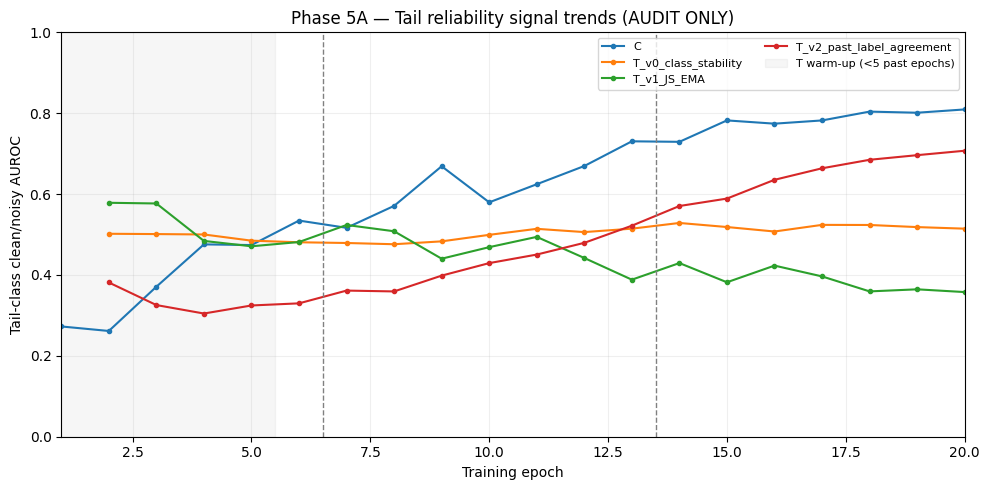

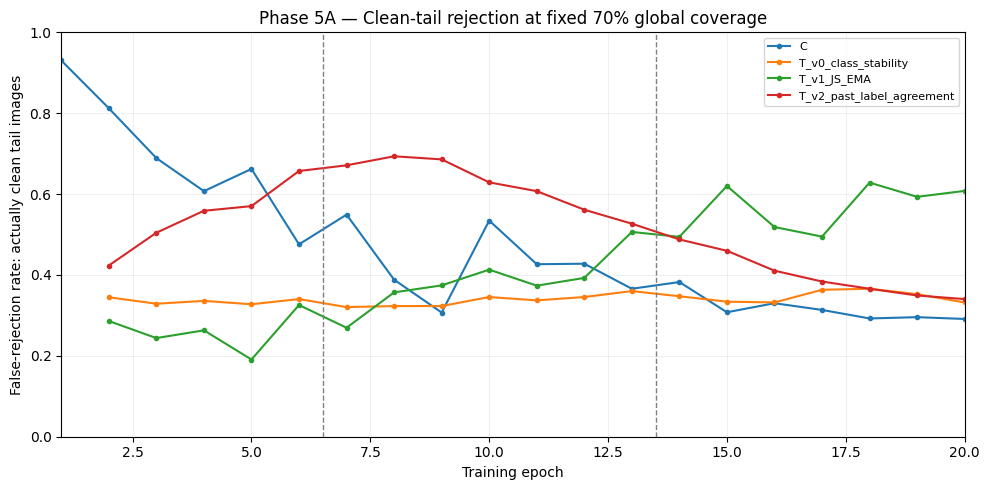

Figures saved under: /content/drive/MyDrive/LTNLL_Research/Phase5A_V2


In [19]:
# P5A.5 — Diagnostic plots; retain all results, including negative ones.
fig, ax = plt.subplots(figsize=(10,5))
for signal_name in P5A_SIGNALS:
    subset = p5a_epoch_table[p5a_epoch_table['signal'] == signal_name]
    ax.plot(subset['epoch'],subset['AUROC_tail'], marker='.', label=signal_name)
ax.axvline(6.5, color='grey', ls='--', lw=1)
ax.axvline(13.5, color='grey', ls='--', lw=1)
ax.axvspan(1.0,5.5, color='grey', alpha=0.07, label='T warm-up (<5 past epochs)')
ax.set(xlabel='Training epoch', ylabel='Tail-class clean/noisy AUROC',
       title='Phase 5A — Tail reliability signal trends (AUDIT ONLY)', ylim=(0,1), xlim=(1,20))
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.2)
fig.tight_layout()
p5a_fig_tail = P5A_OUTPUT / 'phase5A_tail_AUROC_by_epoch_AUDIT_ONLY.png'
fig.savefig(p5a_fig_tail, dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(10,5))
for signal_name in P5A_SIGNALS:
    subset = p5a_epoch_table[p5a_epoch_table['signal'] == signal_name]
    ax.plot(subset['epoch'],subset['clean_tail_false_rejection'],
            marker='.', label=signal_name)
ax.axvline(6.5, color='grey', ls='--', lw=1)
ax.axvline(13.5, color='grey', ls='--', lw=1)
ax.set(xlabel='Training epoch',
       ylabel='False-rejection rate: actually clean tail images',
       title='Phase 5A — Clean-tail rejection at fixed 70% global coverage',
       ylim=(0,1), xlim=(1,20))
ax.legend(fontsize=8)
ax.grid(alpha=0.2)
fig.tight_layout()
p5a_fig_reject = P5A_OUTPUT / 'phase5A_tail_rejection_by_epoch_AUDIT_ONLY.png'
fig.savefig(p5a_fig_reject, dpi=160)
plt.show()
print('Figures saved under:', P5A_OUTPUT)

#A.6 — Save diagnostics and verify everything

In [20]:
# P5A.6 — Save audit metrics separately from ground-truth-free signal histories.
p5a_save_config = {
    'dataset_split_fingerprint':p5a_fp,
    'baseline_validation_selected_epoch':p5a_best_epoch,
    'source_phase2_epochs':int(p5a_epochs),
    'confidence':'p(observed label | image) at each epoch',
    'temporal_window':P5A_WINDOW,
    'EMA_alpha':P5A_EMA_ALPHA,
    'T_v0':'agreement of predicted classes across up to 5 recent transitions',
    'T_v1':'JS similarity with past EMA, excluding current',
    'T_v2':'agreement with observed label over up to 5 PAST epochs',
    'stage_boundaries':{'Early':[1,6], 'Middle':[7,13], 'Late':[14,20]},
    'fixed_history_anchor_epochs':P5A_STAGE_ANCHORS,
    'selection_coverage_fixed_in_advance':P5A_COVERAGE,
    'true_labels_used_only_for_audit':True,
    'stage_weight_schedule_tuned_using_audit_labels':False,
    'neighborhood_N_stagewise_available':False,
    'note':'Offline TRAINING-SPLIT diagnostics only, no stage-weight selection, no retraining, official test unused.',
}
config_file = P5A_OUTPUT / 'phase5A_config.json'
if config_file.exists():
    assert json.loads(config_file.read_text()) == p5a_save_config, (
        'Config differs from existing Phase5A experiment! Use new output folder.'
    )
else:
    config_file.write_text(json.dumps(p5a_save_config, indent=2))

p5a_epoch_file = P5A_OUTPUT / 'phase5A_epochwise_metrics_AUDIT_ONLY.csv'
p5a_anchor_file = P5A_OUTPUT / 'phase5A_anchor_metrics_AUDIT_ONLY.csv'
p5a_scores_file = P5A_OUTPUT / 'phase5A_signal_histories_NO_GROUND_TRUTH.npz'
p5a_epoch_table.to_csv(p5a_epoch_file, index=False)
p5a_anchor_table.to_csv(p5a_anchor_file, index=False)
np.savez_compressed(
    p5a_scores_file,
    original_cifar_index=p5a_indices,
    observed_labels=p5a_observed,
    split_fingerprint=np.asarray(p5a_fp),
    epoch=np.arange(1,p5a_epochs+1,dtype=np.int64),
    C=p5a_C, T_v0=p5a_T_v0, T_v1=p5a_T_v1, T_v2=p5a_T_v2,
)
with np.load(p5a_scores_file, allow_pickle=False) as saved:
    assert saved['C'].shape == (20,p5a_n)
    assert np.array_equal(saved['observed_labels'],p5a_observed)
    assert np.array_equal(saved['original_cifar_index'],p5a_indices)
    assert str(saved['split_fingerprint'].item()) == p5a_fp
    assert not any('clean' in k.lower() or 'noisy' in k.lower() for k in saved.files)
for f in [config_file,p5a_epoch_file,p5a_anchor_file,p5a_scores_file,
          p5a_fig_tail,p5a_fig_reject]:
    assert f.is_file() and f.stat().st_size > 100, str(f)
    print('Saved:',f)
print('\n✅ PHASE 5A STAGE-WISE C/T ANALYSIS CHECKS PASSED')
print('This is offline signal analysis, NOT the stage-aware training algorithm.')
print('Do NOT interpret epoch-20 N as early/middle neighborhood evidence.')

Saved: /content/drive/MyDrive/LTNLL_Research/Phase5A_V2/phase5A_config.json
Saved: /content/drive/MyDrive/LTNLL_Research/Phase5A_V2/phase5A_epochwise_metrics_AUDIT_ONLY.csv
Saved: /content/drive/MyDrive/LTNLL_Research/Phase5A_V2/phase5A_anchor_metrics_AUDIT_ONLY.csv
Saved: /content/drive/MyDrive/LTNLL_Research/Phase5A_V2/phase5A_signal_histories_NO_GROUND_TRUTH.npz
Saved: /content/drive/MyDrive/LTNLL_Research/Phase5A_V2/phase5A_tail_AUROC_by_epoch_AUDIT_ONLY.png
Saved: /content/drive/MyDrive/LTNLL_Research/Phase5A_V2/phase5A_tail_rejection_by_epoch_AUDIT_ONLY.png

✅ PHASE 5A STAGE-WISE C/T ANALYSIS CHECKS PASSED
This is offline signal analysis, NOT the stage-aware training algorithm.
Do NOT interpret epoch-20 N as early/middle neighborhood evidence.
